# 027. 推論サーバ: continuous batching と PagedAttention / Inference Serving: Continuous Batching and PagedAttention

## 1. 概要 / Overview

[010](./010_kv_cache_and_inference_compute.ipynb) は、**1 件の要求** の生成を KV キャッシュ(Key-Value Cache)で速くした。実際の推論サーバ(inference server)は、到着時刻も出力長も違う **多数の要求** を、1 つのデバイスの上で同時に進める。このとき、性能を決めるのは個々の演算ではなく、**どの要求をいつ同じバッチに入れるか(スケジューリング)** と、**要求ごとの KV キャッシュのメモリをどう割り当てるか(メモリ管理)** の 2 つである。

本トピックは、この 2 つを小型 GPT([008](../02_pretraining/008_decoding_strategies.ipynb) の`main`)の上でスクラッチ実装し(`src/serving/`)、次を測る。

- **スケジューリング**: 組を固定してバッチの中で最も長い要求の終わりを待つ **static batching** と、反復ごとに終わった要求を抜いて待っている要求を入れる **continuous batching**(Orca の iteration-level scheduling)。
- **メモリ管理**: 最大長の分を前もって確保する方式と、KV キャッシュを固定長のブロックに分けてブロック表で参照する **PagedAttention**(vLLM)。接頭辞の共有(prefix caching)と書き込み時の複製(copy-on-write)を含む。

学習は行わず、推論だけを扱う。負荷は合成で作る(出力長の平均と変動係数、到着過程を指定する)。検証するのは次の 3 つで、いずれも判定つきである(各実験は 1 つの検証事項を扱う)。

- **実験 A**: 最大バッチサイズを揃え、出力長のばらつきが大きい水準で、continuous batching のスループットが static batching より高いか。
- **実験 B**: 出力長の平均を揃え、変動係数を 4 水準で変えたとき、実験 A の比(continuous / static)が変動係数とともに大きくなるか。隣り合う水準の 3 つの比較(B1・B2・B3)に分けて、部分ごとに判定する。理論の予測(バッチ内の最大長の期待値から求めた比)を診断量として併記する。
- **実験 C**: KV キャッシュの予算(トークン枠の数)を揃え、どちらも continuous batching で動かしたとき、PagedAttention の方が、最大長の分を前もって確保する方式より、反復あたりの実行中の要求数(平均)が多いか。

あわせて、判定を設けない観察として、(D)最大バッチサイズと到着の速さを変えたときの、スループットと、最初のトークンまでの時間(Time To First Token)・出力トークンあたりの時間(Time Per Output Token)の関係、(E)ブロックの大きさを変えたときの内部の断片化と 1 反復の時間、および全要求が同じ system prompt を持つ負荷での接頭辞の共有の効果を示す。観察 D は、アプリ(`apps/`)の段階 2 で最大バッチサイズを決める材料にする。

**この規模の限界(7.11 節)**: 008 の小型 GPT は KV キャッシュが 1 トークンあたり 8,192 バイトで、T4 のメモリに比べて小さく、メモリの制約は実際にはかからない。実験 C の予算は人工的に決めたものである。また、小型モデルの 1 反復の時間は、GPU の計算より Python とカーネルの起動の固定費が支配的になりうる。そのため、スループットの差には、計算量の差より **forward の回数の差** が強く効く。1 反復の時間の行数への依存を測って示す(6.3 節)。

### 1.1 実行の手順

手順は付録 A。本番実行は Google Colab T4 の 1 つのセッション(予算 120 分)で完結させる。

### 1.2 本番実行の結果の要約

本番実行の後に、次を書く(本番実行の前は書かない)。

- 判定の表: 実験ごとに 1 行(A、B1・B2・B3、C)。対比量・閾値・最終判定・1 文の要約。観察 D・E は判定なしと明記して 1 行ずつ。
- 選ばれた計画(削る段階)と、全体の経過時間。

## 2. 参考論文 / References

1. Yu, G.-I., Jeong, J. S., Kim, G.-W., Kim, S., Chun, B.-G. "Orca: A Distributed Serving System for Transformer-Based Generative Models." *OSDI 2022*. https://www.usenix.org/conference/osdi22/presentation/yu — iteration-level scheduling(反復ごとのスケジューリング)と selective batching。**continuous batching の原典。**
2. Kwon, W., Li, Z., Zhuang, S., Sheng, Y., Zheng, L., Yu, C. H., Gonzalez, J. E., Zhang, H., Stoica, I. "Efficient Memory Management for Large Language Model Serving with PagedAttention." *SOSP 2023*. https://arxiv.org/abs/2309.06180 — **PagedAttention と vLLM の原典。** ブロック表・参照数・書き込み時の複製・接頭辞の共有・退避(再計算または swap)。
3. Agrawal, A., Panwar, A., Mohan, J., Kwatra, N., Gulavani, B. S., Ramjee, R. "SARATHI: Efficient LLM Inference by Piggybacking Decodes with Chunked Prefills." *arXiv:2308.16369*, 2023. https://arxiv.org/abs/2308.16369 — chunked prefill(位置づけのみ)。
4. Agrawal, A., Kedia, N., Panwar, A., Mohan, J., Kwatra, N., Gulavani, B. S., Tumanov, A., Ramjee, R. "Taming Throughput-Latency Tradeoff in LLM Inference with Sarathi-Serve." *OSDI 2024*. https://arxiv.org/abs/2403.02310 — スループットと待ち時間の交換(位置づけのみ)。
5. Leviathan, Y., Kalman, M., Matias, Y. "Fast Inference from Transformers via Speculative Decoding." *ICML 2023*. https://arxiv.org/abs/2211.17192 — speculative decoding(位置づけのみ)。

本文中で理論に言及する際は、上の番号で対応する論文を示す。KV キャッシュの閉形式と prefill・decode の性質は [010](./010_kv_cache_and_inference_compute.ipynb) による。

## 3. 理論 / Theory

### 3.1 推論サーバの指標

1 件の要求 $i$ は、書き出し(プロンプト)の長さ $P_i$、出力長 $O_i$、到着時刻 $a_i$ を持つ。出力長は、生成の途中の終端トークンでは止めず、要求に割り当てた長さで止める(出力長の分布を設計どおりに制御するため)。要求 $i$ が最初に実行に入った時刻を $s_i$、最初のトークンを生成した時刻を $f_i$、最後のトークンを生成した時刻を $e_i$ とする。

- **スループット**(throughput): $\Theta = \dfrac{\sum_i O_i}{\max_i e_i - \min_i a_i}$ [トークン / 秒]。
- **最初のトークンまでの時間**(Time To First Token): $W_i = f_i - a_i$。待ち行列の待ちと prefill の時間を含む。
- **出力トークンあたりの時間**(Time Per Output Token): $\tau_i = \dfrac{e_i - f_i}{O_i - 1}$($O_i \ge 2$)。decode の 1 反復の時間と、同じ反復に prefill が割り込む分で決まる。
- **待ち行列の待ち時間**: $q_i = s_i - a_i$。

1 反復(iteration)は、バッチの全行を 1 回の forward で進める処理で、各要求は 1 反復に高々 1 トークンを生成する。decode の 1 反復の時間を、バッチの行数 $n$ の一次式 $t(n) = t_0 + t_1 n$ で近似する($t_0$ は Python とカーネルの起動などの固定費、$t_1$ は 1 行あたりの時間)。行数 $n$ の decode のスループットは $n / t(n)$ で、$n$ を増やすと固定費 $t_0$ が $n$ 行で割られて増え、$1/t_1$ に近づく。一方、出力トークンあたりの時間は $t(n)$ で、$n$ とともに伸びる。**スループットと待ち時間の交換** は、この 2 つの動きから生じる(観察 D で測る)。

### 3.2 static batching の無駄

static batching は、要求の組 $\mathcal{B}$(最大 $B$ 件)を固定し、組の全員が終わるまで次の組を始めない。短い要求が先に終わっても、その行は(捨てる出力のために)計算され続ける。1 組の反復数は $\max_{i \in \mathcal{B}} O_i$、計算した行は $B \max_{i \in \mathcal{B}} O_i$ で、有効な行は $\sum_{i \in \mathcal{B}} O_i$ なので、無駄な行の割合は

$$
1 - \frac{\sum_{i \in \mathcal{B}} O_i}{B \max_{i \in \mathcal{B}} O_i}
$$

である。出力長が独立に同じ分布に従うとき、1 組の反復数の期待値は $\mathbb{E}[\max_B O]$(分布の累積分布関数を $F$ として $\sum_x x \left( F(x)^B - F(x-1)^B \right)$)になる。continuous batching が空いた行を隙間なく詰められる理想的な場合の反復数は $\sum_i O_i / B$ なので、$N$ 件の反復数の比は

$$
\rho_B = \frac{\mathbb{E}[\max_B O]}{\mathbb{E}[O]}
$$

になる(**理論の予測**)。正規分布で近似すると $\mathbb{E}[\max_B O] \approx m (1 + c_v z_B)$(平均 $m$、変動係数 $c_v$、$z_B$ は標準正規分布から $B$ 個を取ったときの最大値の期待値)で、$\rho_B$ は変動係数とともに増える。出力長が揃っている($c_v = 0$)なら $\rho_B = 1$ で、continuous batching の利点はない。ただし、これは **反復の回数の比** で、時間の比ではない。continuous batching は、要求を入れ替えるたびに prefill の forward が 1 回加わる(3.3 節)ので、固定費 $t_0$ が支配的な小型モデルでは、反復の回数の差ほどスループットの差は出ない。

### 3.3 continuous batching(Orca)

Orca(論文 1)は、スケジューリングを **反復ごと**(iteration-level)に行う。1 反復の手順は次のとおりである(図 1)。

1. 到着した要求を待ち行列に入れる。
2. スケジューラが、最大バッチサイズ $B$ とメモリ(KV キャッシュの置き場所)の範囲で、待っている要求を **先着順** に実行に入れる。先頭の要求が入れられないときは、後ろの要求を追い越さない。
3. **prefill**: 入れた要求の文脈(書き出し全体)を 1 回の forward で処理し、最初のトークンを生成する。
4. **decode**: 前の反復から実行中だった要求を、直前に生成したトークンを入力に 1 トークン進める。
5. 終わった要求をバッチから抜き、場所を返す。

```mermaid
%%{init: {"theme": "default"}}%%
flowchart TB
  subgraph ALL[" "]
    A["到着した要求を待ち行列へ"] --> B["待っている要求を先着順に実行へ<br/>(最大バッチサイズとメモリの範囲)"]
    B --> C["prefill: 入れた要求の文脈を<br/>1 回の forward で処理し、最初のトークンを生成"]
    C --> D["decode: 前から実行中の要求を 1 トークン進める"]
    D -- "次のブロックが足りない" --> E["最後に入れた要求を退避(再計算)"]
    E --> D
    D --> F["終わった要求の場所を返す"]
    F --> A
  end
  style ALL fill:#ffffff,stroke:#ffffff
```

*図 1: 本トピックの実行ループ(1 反復)。static batching は、バッチが空になるまで手順 2 で何も入れない点だけが違う。*

Orca は、バッチの全行に共通の演算(射影・正規化・順伝播ネットワーク)は行をまとめ、注意機構だけを要求ごとに処理する **selective batching** で、prefill 中の要求と decode 中の要求を 1 回の forward に混ぜる。本トピックの実装は、prefill と decode を **別々の forward** にする(反復の中で prefill、decode の順)。そのため、要求が入れ替わる反復では forward が 2 回になる。混ぜて 1 回にする設計(chunked prefill、論文 3)は位置づけのみとする(3.7 節)。

最初のトークンまでの時間は、到着から prefill が終わるまでで、待ち行列の待ちを含む。出力トークンあたりの時間は、同じ反復に他の要求の prefill が割り込む分だけ伸びる。

### 3.4 KV キャッシュのメモリ管理の問題

1 トークンの KV キャッシュのバイト数は、010 の閉形式で

$$
m_{\mathrm{tok}} = 2 L g d_k \beta
$$

である($L$ は層数、$g$ は Key / Value ヘッド数、$d_k$ はヘッドあたりの次元、$\beta$ は 1 要素のバイト数)。本モデルでは $2 \times 4 \times 8 \times 32 \times 4 = 8192$ バイトである。デバイスに割り当てる KV キャッシュの予算を、トークン枠の数 $M$ で表す。

出力長は事前に分からないので、**最大長の分を前もって確保する方式** は、要求を受け入れるときにモデルの最大の文脈長 $S_{\max}$ の分を 1 つのスロットとして確保する。同時に処理できる要求の数は $\lfloor M / S_{\max} \rfloor$ に制限される。要求が実際に使う長さは $P + O - 1$(最後のトークンの Key / Value は書き込まれない)で、確保した枠のうち $S_{\max} - (P + O - 1)$ は使われない。これが **内部の断片化**(確保したが使わない枠)である。可変長の連続領域を確保する方式では、解放した領域の間に使えない隙間が生じる **外部の断片化** も起きる。固定長のスロットなら外部の断片化は起きないが、長さを事前に知れないので、最大長に固定する必要がある。

### 3.5 PagedAttention

PagedAttention(論文 2)は、KV キャッシュを **固定長のブロック**($b$ トークン)に分け、要求ごとの **ブロック表**(論理ブロック → 物理ブロック)で参照する(図 2)。要求 $r$ の位置 $p$ のトークンの Key / Value は、物理ブロック $\pi_r(\lfloor p / b \rfloor)$ の、ブロック内の位置 $p \bmod b$ に置く。

```mermaid
%%{init: {"theme": "default"}}%%
flowchart LR
  subgraph ALL[" "]
    subgraph T1["要求 1 のブロック表"]
      A0["論理 0"]
      A1["論理 1"]
      A2["論理 2"]
    end
    subgraph T2["要求 2 のブロック表"]
      B0["論理 0"]
      B1["論理 1"]
    end
    subgraph POOL["物理ブロック(参照数)"]
      P7["物理 7(参照数 2: 共有)"]
      P3["物理 3(1)"]
      P9["物理 9(1)"]
      P5["物理 5(1)"]
    end
    A0 --> P7
    A1 --> P3
    A2 --> P9
    B0 --> P7
    B1 --> P5
  end
  style ALL fill:#ffffff,stroke:#ffffff
```

*図 2: ブロック表。物理 7 は 2 つの要求が共有している(接頭辞の共有、3.6 節)。*

注意機構の計算は変わらない。要求ごとの Query に対し、ブロック表が指す物理ブロックから過去の Key / Value を集めて

$$
\mathrm{softmax}\!\left( \frac{q K^{\top}}{\sqrt{d_k}} \right) V
$$

を計算する($q$ は Query、$K$・$V$ は集めた Key と Value)。本トピックでは、集める処理を PyTorch の添字による参照で書き、専用のカーネルは書かない(3.7 節)。

**無駄は、要求あたり最後のブロックの空きだけ** で、最大で $b - 1$ トークン、つまりブロック 1 つ分未満である。最後のブロックの埋まり方が一様なら、期待値は要求あたり $(b - 1)/2$ トークンになる。したがって、同時に載せられる要求の数は、おおよそ $M / (\bar{S} + (b-1)/2)$($\bar{S}$ は要求が実際に使う長さの平均)で、最大長の分を確保する方式の $\lfloor M / S_{\max} \rfloor$ より、$S_{\max}$ が $\bar{S}$ より大きいほど多い。

**ブロックの大きさ $b$ の選び方** は、断片化と参照の費用の交換である。$b$ が小さいと無駄は小さいが、ブロック表が長くなり、集める添字の数と管理の費用が増える。$b$ が大きいと無駄が増え、$b = S_{\max}$ では最大長の分を確保する方式と同じになる。観察 E で、内部の断片化と 1 反復の時間を測る。

**メモリが足りなくなったとき**(要求が伸びて次のブロックが取れないとき)は、実行中の要求を一時的に取り下げて、ブロックを解放する。方式は 2 つある(論文 2)。**swap** は Key / Value をホストのメモリへ退避し、後で戻す。**再計算**(recompute)は Key / Value を捨て、再開のときに、それまでの文脈(書き出しと生成済みのトークン)を prefill し直す。本トピックは **再計算** を実装する(貪欲法の生成では、再計算しても同じ続きが得られる)。swap は位置づけのみとする。取り下げる要求は、最後に実行に入れたものである。

### 3.6 接頭辞の共有(prefix caching)と書き込み時の複製

複数の要求が同じ接頭辞(system prompt など)を持つとき、その Key / Value は同じなので、物理ブロックを共有できる。各物理ブロックに **参照数** を持たせ、ブロックを共有する要求の数を数える。書き出しの先頭から完全に埋まったブロックごとに、「先頭からそのブロックの終わりまでのトークン列」をキーに登録し、後から来た要求の文脈がそのキーに一致すれば、計算済みのブロックを参照して、その部分の prefill を省く。共有できるのは完全に埋まったブロックだけである(内容が確定していて、書き込まれない)。最後のトークンの logits が要るので、少なくとも 1 トークンは計算し直す。要求が終わって参照数が 0 になった登録済みのブロックは、すぐには捨てず、メモリが足りなくなったときに、最も長く使われていないものから捨てる。

共有しているブロックに書き込むときは、先に複製して自分専用にする(**書き込み時の複製**、copy-on-write)。同じ文脈から複数の続きを生成する場合(並列サンプリング)は、書き込み先の部分的なブロックを共有したまま分岐するので、最初の書き込みで複製が起きる。本トピックの接頭辞の共有は完全なブロックだけを共有するので、実行ループの中で複製は起きない。複製は`fork`(参照数を増やすだけで分岐する)の経路で単体テストする。

### 3.7 位置づけのみの技術

- **chunked prefill**(論文 3、4): 長い prefill を小さな塊に分け、decode と同じ forward に混ぜる。prefill の割り込みで decode が止まる時間(出力トークンあたりの時間の伸び)を抑え、forward の回数も減らせる。本トピックの「反復の中で prefill と decode を別々に forward する」設計の弱点(3.3 節)に直接効く。
- **speculative decoding**(論文 5): 小さなモデルで数トークンを下書きし、大きなモデルが 1 回の forward で検証する。1 反復で複数のトークンを進められる。
- **専用の注意機構のカーネル**: ブロック表を引きながら注意を計算する融合カーネル。本トピックでは、ブロック表の参照を PyTorch の添字(`keys[layer][first, second]`)で書く。集めた Key / Value は一度コピーされるので、メモリの移動量は専用のカーネルより多い。

### 3.8 本トピックの設計上の選択

- 出力長は、要求に割り当てた長さで止める。書き出しの長さと出力長の上限は、合わせてモデルの最大の文脈長(256)に収める。
- 比較する方式は、**同じエンジン**(同じ forward、同じ KV キャッシュの添字の仕組み)の上で、スケジューラとメモリの割り当てだけを入れ替える。違いが方式そのものに由来するようにするためである。
- 時刻は、デバイスの同期を取ってから読む。実行する要求も待っている要求もなく、次の到着まで待つ時間は、実際には待たずに時計を進める(仮想の時計)。計算に使った時間は実測である。

## 4. 実装方針 / Implementation Policy

アプリ(`apps/`)の段階 2 から再利用するため、実装はノートブックではなく`src/serving/`に置く(既存の`src/`の挙動は変えない)。ノートブックには、負荷の水準の定義、実験の実行と判定、図だけを書く。

| 部品 | 場所 | 内容 |
|---|---|---|
| 要求と状態 | `src/serving/requests.py` | 書き出し・出力長・到着時刻を持つ要求と、生成済みのトークンや各時刻を持つ状態 |
| 負荷の生成 | `src/serving/workload.py` | 平均と変動係数を指定した出力長の分布、最大値の期待値、Poisson 過程の到着、書き出しの組み立て |
| KV キャッシュの管理 | `src/serving/kv_store.py` | 最大長の分を前もって確保する方式(スロット)と、PagedAttention(ブロック表・参照数・書き込み時の複製・接頭辞の共有) |
| 実行器 | `src/serving/runner.py` | 長さの違う要求を 1 回の forward で進める(行ごとの RoPE の位置、ブロック表からの Key / Value の読み書き) |
| スケジューラ | `src/serving/scheduler.py` | static batching と continuous batching |
| 実行ループ | `src/serving/engine.py` | 反復ごとのスケジューリング、prefill・decode、退避(再計算)、各時刻の記録 |
| 時計と費用モデル | `src/serving/clock.py` | デバイスの同期を取る時計と、1 反復の時間の一次式による見積もり用の時計 |
| 指標 | `src/serving/metrics.py` | スループット、最初のトークンまでの時間、出力トークンあたりの時間、メモリの使用状況 |
| 基準と許容誤差 | `src/serving/reference.py` | 010 の KV キャッシュによる 1 要求ずつの生成と、計算する型から導く許容誤差 |

**スクラッチ実装** するのは、スケジューラ、KV キャッシュの割り当て(ブロック管理)、バッチの forward である。学習済みの重み、正規化、順伝播ネットワーク、射影は、既存の層をそのまま使う(注意機構の部分だけを、行ごとの位置を扱う形で書き直した)。単体テストは`scripts/test_serving.py`にあり(5.4 節で実行する)、1 要求ずつの生成との一致、ブロックの確保と解放の整合、書き込み時の複製などを確かめる。

## 5. 実装 / Implementation

### 5.1 セットアップ

In [1]:
# 環境セットアップ(Google Colab)
import os
import sys
import time

SMOKE_TEST = True  # True: 縮小スケールでの動作確認、False: 本番(Colab T4 の 1 セッション)

NOTEBOOK_START_TIME = time.time()

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("/content/ai-theories"):  # 2 回目の実行では clone し直さない
        !git clone https://github.com/kojikojiprg/ai-theories.git /content/ai-theories
    %cd /content/ai-theories
    !pip install uv -q
    !uv pip install --system -r requirements.txt

# インストールで版が入れ替わったパッケージの古い版がメモリに残っていないかを、torch などを import する前に確かめる。
# Colab では食い違いがあればカーネルを終了する(再接続後、もう一度「すべてのセルを実行」する)
from src.utils.environment import check_preloaded_package_versions  # noqa: E402

check_preloaded_package_versions(on_mismatch="restart" if IN_COLAB else "raise")

import torch  # noqa: E402

from src.utils.environment import print_execution_environment  # noqa: E402

device = torch.device(
    "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
)
execution_environment = print_execution_environment(device)

# 本番(SMOKE_TEST = False)は、追跡しているファイルに未コミットの変更がない状態で実行する
if not SMOKE_TEST:
    import subprocess

    _head = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
    _status = subprocess.run(
        ["git", "status", "--porcelain", "--untracked-files=no"], capture_output=True, text=True, check=True
    ).stdout.strip()
    if _status:
        raise RuntimeError(
            f"本番の実行条件を満たさないため、学習の前に停止する(結果の情報は何も得ていない)。HEAD {_head[:7]}、"
            f"追跡しているファイルの未コミットの変更: {_status}。"
        )
    print(f"本番の実行条件: HEAD {_head[:7]}、追跡しているファイルに未コミットの変更がない: OK")
print(f"SMOKE_TEST={SMOKE_TEST}、計算の型 FP32(貪欲法で生成する。学習は行わない)")

読み込み済みのパッケージの版の検査(requirements.txt): 食い違いなし。検査した配布物 3 個(packaging==26.3, python-dateutil==2.9.0.post0, six==1.17.0)、未読み込みのため検査しなかった配布物 51 個、__version__ がないため比べなかった配布物 1 個(typing-extensions)、表記の違いで誤検出するため比べなかった配布物 0 個(なし)


実行環境 / Execution environment
  Python                                 : 3.12.11
  OS / platform                          : macOS-26.6.2-arm64-arm-64bit
  torch                                  : 2.13.0
  torch のビルド時の CUDA                : 該当なし
  cuDNN                                  : 該当なし
  デバイス / device                      : mps
  GPU 名 / GPU name                      : 該当なし
  compute capability                     : 該当なし
  GPU の総メモリ (GiB)                   : 該当なし
  コミット / git commit                  : 9fe286dbf9b968dedd3cb573a2360986b0a4ec9c
  未コミットの変更 / uncommitted changes : あり
  実行日時 (UTC)                         : 2026-10-18T04:51:51+00:00
SMOKE_TEST=True、計算の型 FP32(貪欲法で生成する。学習は行わない)


In [2]:
import functools
import gc
import hashlib
import io
import json
import math
import unittest
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from huggingface_hub import hf_hub_download

from src.data.retrieval import find_articles_starting_at_or_after
from src.data.text import locate_wikipedia_article_spans
from src.data.tokenizer import load_bpe_id_tokenizer_from_hub
from src.layers.feedforward import SwiGLUFeedForwardNetwork
from src.layers.normalization import RMSNorm
from src.layers.positional_encoding import RotaryPositionEmbedding
from src.models.gpt import GPTLanguageModel
from src.serving import (
    ContinuousBatchScheduler,
    DryRunner,
    IterationCostModel,
    ModelClock,
    ModelRunner,
    PagedKeyValueStore,
    Request,
    RequestState,
    ReservedKeyValueStore,
    Row,
    ServingEngine,
    ServingModel,
    StaticBatchScheduler,
    WallClock,
    build_requests,
    fit_cost_model,
    fit_output_length_distribution,
    latency_statistics,
    logits_tolerance,
    mean_active_requests,
    memory_statistics,
    moment_sampling_distribution,
    poisson_arrival_times,
    predicted_static_to_continuous_ratio,
    reference_generate,
    sample_output_lengths,
    sample_prompt_lengths,
    throughput,
    wasted_row_fraction,
)
from src.utils.device import synchronize_device
from src.utils.statistics import fit_power_law_exponent

ROOT = Path.cwd()
WIKIPEDIA_CACHE_DIR = ROOT / ".cache" / "wikipedia_en"  # 記事の境界は metadata.json から得るので、Wikipedia API には接続しない

/Users/koji/projects/ai-theories/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 5.2 スケールの設定(`SMOKE_TEST`)

`SMOKE_TEST = True`は、コードの経路が最後まで通ることだけを確かめる縮小スケールで、数値に意味はない。縮小は本番の構造(比率・順序関係・一致関係)を保つ(付録 D)。

In [3]:
# --- 全水準で共通の定数(本番実行前に宣言し、SMOKE_TEST で変えない) ---
MODEL_REPO_ID = "kojikojiprg/ai-theories-small-gpt-en"  # main ブランチ(008 の事前学習済みの小型 GPT、多頭注意機構)
TOKENIZER_REPO_ID = "kojikojiprg/ai-theories-tokenizer-en"
CORPUS_REPO_ID = "kojikojiprg/ai-theories-corpus-en"  # 9,826 記事(en_009_scaling.json)。先頭に参照コーパスを含む
REFERENCE_CORPUS_REPO_ID = "kojikojiprg/ai-theories-corpus-en-pretraining"  # 008 の事前学習に使った 356 記事
MANIFEST_PATH = Path("src/data/wikipedia_manifests/en_009_scaling.json")
VALIDATION_RATIO = 0.05  # コーパスの末尾 5% を検証用とする(009 の分割。metadata.json の validation_ratio と一致させる)
HEAD_CHARACTERS = 2000  # 記事の先頭から書き出しを切り出す文字数(トークン数に十分な余裕がある)

VARIATION_LEVELS = (0.25, 0.5, 0.75, 1.0)  # 実験 B の出力長の変動係数の水準(刻みは等間隔。理由は付録 B.5)
VARIATION_A = 1.0  # 実験 A の水準(= 実験 B の最上位の水準と同じ実行を使う)
VARIATION_C = 0.5  # 実験 C・観察 D・E の水準
SEED_TIERS = (8, 5, 3, 2)  # 実験 A・B・C のシード数(削る前から順に)
PILOT_SEEDS = (90, 91, 92)  # パイロット専用のシード(本番のシード 0〜7 と重ならない)
TIMING_REPEATS = 3  # パイロットで、同じ負荷を繰り返して測る回数
SIGMA_MULTIPLIER = 2.0  # 判定の閾値は対比量の標準偏差の 2 倍
TIMING_VARIATION_THRESHOLD = 0.05  # 前提条件 P2: 同じ条件の反復のスループットの変動係数
RESERVED_UTILIZATION_LIMIT = 0.5  # 前提条件 P4: 予約方式の枠の使用率の上限(実験 C)
STATIC_RATIO_FLOOR = 1.5  # 前提条件 P3: 実験 A の水準の、理論の比(E[max] / E[O])の下限
RHO_LEVELS = (0.4, 0.8, 1.2)  # 観察 D の到着の速さ(オフラインの処理能力に対する比)
SESSION_BUDGET_SECONDS = 120 * 60  # 1 セッションの予算(T4 で 120 分)
CONSERVATIVE_EFFECT_FACTOR = 0.5  # 検出力の確認で、理論の効果をこの倍率に割り引く(付録 B.2)
HEADROOM_BLOCKS_PER_RUNNING = 1  # 実験 C の PagedAttention の、実行中の要求 1 つあたりの空きブロックの余白

# --- 水準によって変える値(SMOKE_TEST は縮小スケール。比率・順序関係・一致関係を保つ。付録 D) ---
def level(production, smoke):
    return smoke if SMOKE_TEST else production


NUM_REQUESTS = level(128, 32)  # 1 回の実行の要求数 N(最大バッチサイズの 8 倍)
PROMPT_RANGE = level((16, 48), (2, 6))  # 書き出しの長さの範囲(出力長の平均との比が 2/3)
OUTPUT_MEAN = level(48, 6)
OUTPUT_MIN = 1
OUTPUT_MAX = level(192, 24)  # 出力長の上限(平均の 4 倍)
MAX_BATCH_SIZE = level(16, 4)  # 実験 A・B・C の最大バッチサイズ B
RESERVED_SLOTS_C = level(4, 1)  # 実験 C の予算 = この数の最大長のスロット(B の 1/4)
BLOCK_SIZE = level(16, 2)  # 既定のブロックの大きさ(書き出しの平均の長さの 1/2)
BLOCK_SIZES_E = level((4, 8, 16, 32, 64), (1, 2, 4, 8, 16))  # 観察 E のブロックの大きさ(等比)
OBSERVATION_BATCH_SIZES = level((1, 2, 4, 8, 16, 32), (1, 2, 4, 8))  # 観察 D の最大バッチサイズ(等比)
NUM_REQUESTS_OBSERVATION = level(96, 24)
SYSTEM_PROMPT_LENGTH = level(64, 8)  # 観察 E の共通の system prompt(既定のブロックの 4 つ分)
USER_PROMPT_RANGE = level((8, 24), (1, 3))
PREFIX_OUTPUT_MEAN = level(32, 4)
PREFIX_OUTPUT_MAX = level(96, 12)
PROMPT_POOL_ARTICLES = level(300, 40)  # 書き出しを切り出す検証用の記事の数
PILOT_DECODE_ROWS = level((1, 2, 4, 8, 16, 32), (1, 2, 4, 8))
PILOT_DECODE_REPEATS = level(30, 5)
PILOT_CONTEXT_LENGTH = level(56, 7)  # decode の計測で各行が持つ文脈の長さ(書き出しの平均 + 出力の平均の半分)
PILOT_PREFILL_SHAPES = level(
    ((1, 16), (1, 48), (4, 32), (8, 32), (8, 48), (16, 48)), ((1, 2), (1, 6), (2, 4), (4, 4), (4, 6), (8, 6))
)  # (行数, 問い合わせの長さ)

# 削る段階(番号が大きいほど多く削る。各段階は前の段階に変更を加える。選び方は 6.5 節)
STAGES = [
    dict(change="(削らない)", seeds=SEED_TIERS[0], observation_seeds=2, rates=RHO_LEVELS, batch_sizes=OBSERVATION_BATCH_SIZES, blocks=BLOCK_SIZES_E),
    dict(change="観察 D・E のシード数を 1 にする", seeds=SEED_TIERS[0], observation_seeds=1, rates=RHO_LEVELS, batch_sizes=OBSERVATION_BATCH_SIZES, blocks=BLOCK_SIZES_E),
    dict(change="観察 D・E の水準を 1 つおきにする", seeds=SEED_TIERS[0], observation_seeds=1, rates=(RHO_LEVELS[0], RHO_LEVELS[2]), batch_sizes=OBSERVATION_BATCH_SIZES[::2], blocks=BLOCK_SIZES_E[::2]),
    dict(change=f"実験 A・B・C のシード数を {SEED_TIERS[1]} にする", seeds=SEED_TIERS[1], observation_seeds=1, rates=(RHO_LEVELS[0], RHO_LEVELS[2]), batch_sizes=OBSERVATION_BATCH_SIZES[::2], blocks=BLOCK_SIZES_E[::2]),
    dict(change=f"実験 A・B・C のシード数を {SEED_TIERS[2]} にする", seeds=SEED_TIERS[2], observation_seeds=1, rates=(RHO_LEVELS[0], RHO_LEVELS[2]), batch_sizes=OBSERVATION_BATCH_SIZES[::2], blocks=BLOCK_SIZES_E[::2]),
    dict(change=f"実験 A・B・C のシード数を {SEED_TIERS[3]} にする", seeds=SEED_TIERS[3], observation_seeds=1, rates=(RHO_LEVELS[0], RHO_LEVELS[2]), batch_sizes=OBSERVATION_BATCH_SIZES[::2], blocks=BLOCK_SIZES_E[::2]),
]
NUM_STAGES = len(STAGES)
for _earlier, _later in zip(STAGES, STAGES[1:], strict=False):  # 段階が進むと水準は減る一方である
    assert _later["seeds"] <= _earlier["seeds"] and _later["observation_seeds"] <= _earlier["observation_seeds"]
    assert len(_later["rates"]) <= len(_earlier["rates"]) and len(_later["batch_sizes"]) <= len(_earlier["batch_sizes"])
print(f"水準: {'縮小(SMOKE_TEST)' if SMOKE_TEST else '本番'}、要求数 N = {NUM_REQUESTS}、最大バッチサイズ B = {MAX_BATCH_SIZE}、"
      f"書き出し {PROMPT_RANGE}、出力長 平均 {OUTPUT_MEAN}・範囲 [{OUTPUT_MIN}, {OUTPUT_MAX}]、ブロック {BLOCK_SIZE}")

水準: 縮小(SMOKE_TEST)、要求数 N = 32、最大バッチサイズ B = 4、書き出し (2, 6)、出力長 平均 6・範囲 [1, 24]、ブロック 2


### 5.3 モデルとデータ

モデルは 008 の`main`(多頭注意機構)、トークナイザは`ai-theories-tokenizer-en`。要求の書き出しは、`ai-theories-corpus-en`の検証用の記事(コーパスの末尾 5%)の先頭から切り出す。検証用の記事はすべて、008 が事前学習で見た範囲(先頭の 356 記事の前半)の外にある。書き出しの内容は計測の対象ではない(出力長を割り当てた長さで止めるので、どの書き出しでも同じ量の処理になる)。

In [4]:
# --- トークナイザ・モデル(008 がアップロードした main) ---
_stage_start = time.time()
tokenizer, _tokenizer_from_hub = load_bpe_id_tokenizer_from_hub(TOKENIZER_REPO_ID)
assert _tokenizer_from_hub, "トークナイザを Hugging Face Hub から取得できなかった"
config = json.loads(Path(hf_hub_download(MODEL_REPO_ID, "config.json")).read_text(encoding="utf-8"))
assert tokenizer.vocab_size == config["vocabulary_size"]
for _name, _expected in (("positional_encoding", "rope"), ("normalization", "rmsnorm"), ("feed_forward", "swiglu")):
    assert config[_name] == _expected, f"config.json の {_name} が想定と違う"
assert config.get("num_key_value_heads") in (None, config["num_heads"]), "main は多頭注意機構(g = h)であるはず"
MODEL_MAX_LENGTH = config["sequence_length"]
head_dim = config["d_model"] // config["num_heads"]
model = GPTLanguageModel(
    vocabulary_size=config["vocabulary_size"], d_model=config["d_model"], num_layers=config["num_layers"],
    num_heads=config["num_heads"], d_ff=config["d_ff"], max_sequence_length=MODEL_MAX_LENGTH,
    positional_transform=RotaryPositionEmbedding(head_dim, max_position=MODEL_MAX_LENGTH),
    normalization_factory=RMSNorm,
    feed_forward_factory=functools.partial(SwiGLUFeedForwardNetwork, config["d_model"], config["swiglu_d_ff"]),
    tie_embeddings=config["tie_embeddings"], dropout=config["dropout"],
)
model.load_state_dict(torch.load(hf_hub_download(MODEL_REPO_ID, "model_state.pt"), map_location="cpu"))
model.eval()
for _parameter in model.parameters():
    _parameter.requires_grad_(False)
model.to(device)
assert next(model.parameters()).dtype == torch.float32
SERVING_MODEL = ServingModel(model)
RUNNER = ModelRunner(SERVING_MODEL)
NUM_LAYERS, NUM_KEY_VALUE_HEADS = SERVING_MODEL.num_layers, SERVING_MODEL.num_key_value_heads
KEY_VALUE_BYTES_PER_TOKEN = 2 * NUM_LAYERS * NUM_KEY_VALUE_HEADS * head_dim * 4  # 010 の閉形式(FP32)
print(f"モデル: 層数 {NUM_LAYERS}、d_model {config['d_model']}、ヘッド数 {config['num_heads']}(Key / Value も {NUM_KEY_VALUE_HEADS})、"
      f"最大の文脈長 {MODEL_MAX_LENGTH}、語彙 {config['vocabulary_size']}、1 トークンの KV キャッシュ {KEY_VALUE_BYTES_PER_TOKEN:,} バイト"
      f"({time.time() - _stage_start:.1f} 秒)")

# 要求の長さの設計: 書き出し + 出力が、モデルの最大の文脈長に収まる(KV キャッシュに載る長さは書き出し + 出力 - 1)
assert PROMPT_RANGE[1] + OUTPUT_MAX <= MODEL_MAX_LENGTH, "書き出しと出力の上限の和が最大の文脈長を超える"
assert SYSTEM_PROMPT_LENGTH + USER_PROMPT_RANGE[1] + PREFIX_OUTPUT_MAX <= MODEL_MAX_LENGTH
assert PROMPT_RANGE[1] + OUTPUT_MAX - 1 <= MODEL_MAX_LENGTH
print(f"要求の長さの上限: 書き出し {PROMPT_RANGE[1]} + 出力 {OUTPUT_MAX} = {PROMPT_RANGE[1] + OUTPUT_MAX} <= 最大の文脈長 {MODEL_MAX_LENGTH}")

# --- コーパス: 検証用の記事から書き出しを切り出す ---
_stage_start = time.time()
_reference_text = Path(hf_hub_download(REFERENCE_CORPUS_REPO_ID, "corpus.txt", repo_type="dataset")).read_text(encoding="utf-8")
_corpus_path = hf_hub_download(CORPUS_REPO_ID, "corpus.txt", repo_type="dataset")
_metadata_path = hf_hub_download(CORPUS_REPO_ID, "metadata.json", repo_type="dataset")
_metadata = json.loads(Path(_metadata_path).read_text(encoding="utf-8"))
assert _metadata["manifest"] == MANIFEST_PATH.name and "article_offsets" in _metadata
assert _metadata["validation_ratio"] == VALIDATION_RATIO, "metadata.json の検証用の割合が想定と違う"
assert os.path.getsize(_corpus_path) == _metadata["raw_bytes"], "コーパスの取得が破損している"
corpus_text = Path(_corpus_path).read_text(encoding="utf-8")
assert corpus_text.startswith(_reference_text), "先頭が 008 の事前学習に使った参照コーパスと一致しない"
article_spans, _spans_source = locate_wikipedia_article_spans(
    corpus_text, "en", WIKIPEDIA_CACHE_DIR, MANIFEST_PATH, metadata_path=_metadata_path
)
assert _spans_source == "metadata"
_validation_start = len(corpus_text) - int(len(corpus_text) * VALIDATION_RATIO)  # split_train_val_text と同じ境界
VALIDATION_ARTICLES = find_articles_starting_at_or_after(article_spans, _validation_start)
assert _validation_start > len(_reference_text), "検証用の範囲が、008 が事前学習で見た範囲と重なる"
NUM_CORPUS_ARTICLES, NUM_VALIDATION_ARTICLES = len(article_spans), len(VALIDATION_ARTICLES)

_needed_tokens = max(PROMPT_RANGE[1], USER_PROMPT_RANGE[1], SYSTEM_PROMPT_LENGTH)
_picked = [VALIDATION_ARTICLES[int(i)] for i in np.linspace(0, len(VALIDATION_ARTICLES) - 1, PROMPT_POOL_ARTICLES + 8).astype(int)]
_heads: list[list[int]] = []
for _article in dict.fromkeys(_picked):  # 重複を除く(順序は保つ)
    _span = article_spans[_article]
    _ids = tokenizer.encode(corpus_text[_span["start"] : min(_span["start"] + HEAD_CHARACTERS, _span["end"])])
    if len(_ids) >= _needed_tokens:
        _heads.append(_ids[:_needed_tokens])
SYSTEM_PROMPT = tuple(_heads[0][:SYSTEM_PROMPT_LENGTH])  # 観察 E の共通の system prompt
PROMPT_POOL = _heads[1 : PROMPT_POOL_ARTICLES + 1]
assert len(PROMPT_POOL) >= PROMPT_POOL_ARTICLES // 2, "書き出しの候補が足りない"
assert all(0 <= t < tokenizer.vocab_size for head in PROMPT_POOL for t in head)
assert tokenizer.decode(tokenizer.encode(corpus_text[article_spans[VALIDATION_ARTICLES[0]]["start"] :][:3000])) == corpus_text[article_spans[VALIDATION_ARTICLES[0]]["start"] :][:3000]
del corpus_text, _reference_text
gc.collect()
print(
    f"コーパス: {NUM_CORPUS_ARTICLES:,} 記事のうち検証用の記事 {NUM_VALIDATION_ARTICLES:,}(008 の事前学習の範囲の外)。"
    f"書き出しの候補 {len(PROMPT_POOL)} 本(各 {_needed_tokens} トークン)、system prompt {len(SYSTEM_PROMPT)} トークン({time.time() - _stage_start:.1f} 秒)"
)

モデル: 層数 4、d_model 256、ヘッド数 8(Key / Value も 8)、最大の文脈長 256、語彙 8192、1 トークンの KV キャッシュ 8,192 バイト(0.8 秒)
要求の長さの上限: 書き出し 6 + 出力 24 = 30 <= 最大の文脈長 256


コーパス: 9,826 記事のうち検証用の記事 434(008 の事前学習の範囲の外)。書き出しの候補 40 本(各 8 トークン)、system prompt 8 トークン(2.5 秒)


### 5.4 単体テストと、負荷・実行のヘルパー

`src/serving/`の単体テストを実行し、続いて負荷の生成・実行・見積もりのヘルパーを定義する。

In [5]:
# --- src/serving/ の単体テスト(乱数の重みの小さなモデル。Hugging Face Hub は使わない) ---
_stage_start = time.time()
sys.path.insert(0, str(ROOT / "scripts"))
import test_serving  # noqa: E402

_suite = unittest.defaultTestLoader.loadTestsFromModule(test_serving)
_stream = io.StringIO()
_test_result = unittest.TextTestRunner(stream=_stream, verbosity=0).run(_suite)
UNIT_TEST_COUNT = _test_result.testsRun
assert _test_result.wasSuccessful(), _stream.getvalue()
print(f"src/serving/ の単体テスト: {UNIT_TEST_COUNT} 件すべて成功({time.time() - _stage_start:.1f} 秒)")

src/serving/ の単体テスト: 57 件すべて成功(2.5 秒)


In [6]:
# --- 出力長の分布(平均・変動係数が水準の値に一致する)と、負荷の生成 ---
DISTRIBUTIONS = {variation: fit_output_length_distribution(OUTPUT_MEAN, variation, OUTPUT_MIN, OUTPUT_MAX) for variation in VARIATION_LEVELS}
PREFIX_DISTRIBUTION = fit_output_length_distribution(PREFIX_OUTPUT_MEAN, VARIATION_C, OUTPUT_MIN, PREFIX_OUTPUT_MAX)
for _variation, _d in DISTRIBUTIONS.items():
    assert abs(_d.mean - OUTPUT_MEAN) < 1e-6 and abs(_d.coefficient_of_variation - _variation) < 1e-6
assert VARIATION_A == max(VARIATION_LEVELS) and VARIATION_C in VARIATION_LEVELS
assert (OUTPUT_MAX - OUTPUT_MIN) // OUTPUT_MEAN >= 3  # 範囲が平均の 3 倍以上ある(変動係数 1 の分布を切り詰めすぎない)
THEORY_RATIO = {variation: predicted_static_to_continuous_ratio(d, MAX_BATCH_SIZE) for variation, d in DISTRIBUTIONS.items()}
assert [THEORY_RATIO[variation] for variation in VARIATION_LEVELS] == sorted(THEORY_RATIO.values())
print("出力長の分布(切り詰めたガンマ分布の形。平均と変動係数が水準の値に一致するように形状と尺度を解いた):")
for _variation, _d in DISTRIBUTIONS.items():
    print(f"  変動係数 = {_variation:.2f}: 形状 k = {_d.shape:.3f}、尺度 = {_d.scale:.2f}、上限 {_d.maximum} の確率 {_d.probabilities[-1]:.4f}、"
          f"理論の比 E[max_{MAX_BATCH_SIZE} O] / E[O] = {THEORY_RATIO[_variation]:.3f}")


def make_requests(variation: float, seed: int, count: int = NUM_REQUESTS, arrival_rate: float | None = None, prefix: bool = False) -> list[Request]:
    """シードごとに決定的な負荷(出力長・書き出しの長さ・書き出しの選択・到着時刻)。"""
    rng = np.random.default_rng([seed, int(round(variation * 100)), int(prefix)])
    if prefix:
        outputs = sample_output_lengths(PREFIX_DISTRIBUTION, count, rng)
        prompts = sample_prompt_lengths(*USER_PROMPT_RANGE, count, rng)
        shared = SYSTEM_PROMPT
    else:
        outputs = sample_output_lengths(DISTRIBUTIONS[variation], count, rng)
        prompts = sample_prompt_lengths(*PROMPT_RANGE, count, rng)
        shared = ()
    # 到着の乱数は別の系列から引く(書き出し・出力長の乱数を消費しない)ので、同じシードの負荷は到着率が違っても中身が同じ
    arrivals = np.zeros(count) if arrival_rate is None else poisson_arrival_times(arrival_rate, count, np.random.default_rng([seed, 7, int(prefix)]))
    requests = build_requests(PROMPT_POOL, prompts, outputs, arrivals, rng, shared_prefix=shared)
    for r in requests:
        assert r.prompt_length + r.output_length - 1 <= MODEL_MAX_LENGTH
    return requests


def load_digest(requests) -> str:
    return hashlib.sha256(repr([(r.prompt_token_ids, r.output_length, r.arrival_time) for r in requests]).encode()).hexdigest()[:12]


@dataclass(frozen=True)
class RunSpec:
    """1 回の実行の条件(実行と見積もりの両方に使う)。"""

    experiment: str  # "AB"・"C"・"D"・"E1"・"E2"
    variation: float
    seed: int
    scheduler: str  # "static" または "continuous"
    store_kind: str  # "paged" または "reserved"
    batch_size: int
    block_size: int = BLOCK_SIZE
    num_blocks: int | None = None  # None のとき、最大バッチサイズ分の最大長を載せられる数(予算に制約がかからない)
    num_slots: int | None = None
    prefix_caching: bool = False
    shared_prefix: bool = False
    arrival_factor: float | None = None  # None: 全要求が最初に到着(一括処理)。数値: 到着率 = この値 × LAMBDA_REFERENCE
    count: int = NUM_REQUESTS
    headroom: int = 0


LAMBDA_REFERENCE: float | None = None  # 6.4 節のパイロットで決める(要求 / 秒)


def ample_blocks(batch_size: int, block_size: int) -> int:
    return batch_size * -(-MODEL_MAX_LENGTH // block_size)


def spec_requests(spec: RunSpec) -> list[Request]:
    rate = None if spec.arrival_factor is None else spec.arrival_factor * LAMBDA_REFERENCE
    return make_requests(spec.variation, spec.seed, spec.count, rate, spec.shared_prefix)


def build_store(spec: RunSpec, materialize: bool = True):
    common = dict(num_layers=NUM_LAYERS, num_key_value_heads=NUM_KEY_VALUE_HEADS, head_dim=head_dim, device=device, materialize=materialize)
    if spec.store_kind == "paged":
        return PagedKeyValueStore(
            num_blocks=spec.num_blocks or ample_blocks(spec.batch_size, spec.block_size), block_size=spec.block_size,
            enable_prefix_caching=spec.prefix_caching, headroom_blocks_per_running=spec.headroom, **common,
        )
    return ReservedKeyValueStore(num_slots=spec.num_slots or spec.batch_size, slot_length=MODEL_MAX_LENGTH, **common)


def build_scheduler(spec: RunSpec):
    return (StaticBatchScheduler if spec.scheduler == "static" else ContinuousBatchScheduler)(spec.batch_size)


def summarize(result, store, requests, compute_seconds: float) -> dict:
    iterations = result.iterations
    units = [it.units_in_use for it in iterations]
    return dict(
        throughput=throughput(result), makespan=result.makespan, iterations=len(iterations), compute_seconds=compute_seconds,
        active_mean=mean_active_requests(result), wasted_rows=wasted_row_fraction(result), preemptions=result.num_preemptions,
        mean_iteration_seconds=compute_seconds / len(iterations), forwards=sum((it.prefill_rows > 0) + (it.decode_rows > 0) for it in iterations),
        units_mean=float(np.mean(units)), units_peak=int(max(units)),
        prefix_hit_blocks=getattr(store, "num_prefix_hit_blocks", 0), digest=load_digest(requests),
        prompt_mean=float(np.mean([r.prompt_length for r in requests])), output_mean=float(np.mean([r.output_length for r in requests])),
        active_series=[it.active_requests for it in iterations],
        **latency_statistics(result), **memory_statistics(result),
    )


def execute(spec: RunSpec) -> dict:
    """1 回の実行。生成したトークンの数と、メモリの条件(退避の有無)を、その場で確かめる。"""
    started = time.perf_counter()
    requests = spec_requests(spec)
    store = build_store(spec)
    engine = ServingEngine(build_scheduler(spec), store, RUNNER, WallClock(device))
    synchronize_device(device)
    overhead = time.perf_counter() - started
    result = engine.run(requests)
    compute_seconds = sum(it.end_time - it.start_time for it in result.iterations)
    assert all(len(result.generated[r.request_id]) == r.output_length for r in requests), "出力長どおりに生成されていない"
    if spec.experiment != "C":
        assert result.num_preemptions == 0, f"予算に制約がかからないはずの実行で退避が起きた: {spec}"
    summary = summarize(result, store, requests, compute_seconds)
    summary["overhead_seconds"] = overhead
    del engine, store
    return summary


def estimate_seconds(spec: RunSpec, cost_model: IterationCostModel) -> float:
    """モデルを実行せず、スケジューラとメモリ管理だけを費用モデルの時計で進めて、計算時間を見積もる。"""
    store = build_store(spec, materialize=False)
    result = ServingEngine(build_scheduler(spec), store, DryRunner(), ModelClock(cost_model)).run(spec_requests(spec))
    return sum(it.end_time - it.start_time for it in result.iterations)


PAGED_BLOCKS_C = RESERVED_SLOTS_C * MODEL_MAX_LENGTH // BLOCK_SIZE  # 実験 C の予算: 最大長のスロット RESERVED_SLOTS_C 個分のトークン枠


def c_spec(kind: str, seed: int) -> RunSpec:
    """実験 C の条件。2 つの方式は、同じ予算(トークン枠の総数)・同じ最大バッチサイズ・同じ負荷で、どちらも continuous batching。"""
    if kind == "paged":
        return RunSpec("C", VARIATION_C, seed, "continuous", "paged", MAX_BATCH_SIZE, num_blocks=PAGED_BLOCKS_C, headroom=HEADROOM_BLOCKS_PER_RUNNING)
    return RunSpec("C", VARIATION_C, seed, "continuous", "reserved", MAX_BATCH_SIZE, num_slots=RESERVED_SLOTS_C)


def planned_runs(stage_index: int) -> list[RunSpec]:
    """段階 ``stage_index`` で実行する条件の一覧(実行と見積もりで同じものを使う)。"""
    stage = STAGES[stage_index]
    specs: list[RunSpec] = []
    for seed in range(stage["seeds"]):
        for index, variation in enumerate(VARIATION_LEVELS):  # 実験 A・B: 時間の偏りを避けるため、方式の順番を入れ替える
            order = ("continuous", "static") if (seed + index) % 2 == 0 else ("static", "continuous")
            specs += [RunSpec("AB", variation, seed, name, "paged", MAX_BATCH_SIZE) for name in order]
    for seed in range(stage["seeds"]):
        order = ("paged", "reserved") if seed % 2 == 0 else ("reserved", "paged")
        specs += [c_spec(kind, seed) for kind in order]
    for seed in range(stage["observation_seeds"]):
        for rho in stage["rates"]:
            specs += [
                RunSpec("D", VARIATION_C, seed, "continuous", "paged", b, arrival_factor=rho, count=NUM_REQUESTS_OBSERVATION)
                for b in stage["batch_sizes"]
            ]
        specs += [
            RunSpec("E1", VARIATION_C, seed, "continuous", "paged", MAX_BATCH_SIZE, block_size=bs, count=NUM_REQUESTS_OBSERVATION)
            for bs in stage["blocks"]
        ]
        specs.append(RunSpec("E1", VARIATION_C, seed, "continuous", "reserved", MAX_BATCH_SIZE, count=NUM_REQUESTS_OBSERVATION))
        specs += [
            RunSpec("E2", VARIATION_C, seed, "continuous", "paged", MAX_BATCH_SIZE, prefix_caching=prefix, shared_prefix=True,
                    arrival_factor=RHO_LEVELS[0], count=NUM_REQUESTS_OBSERVATION)
            for prefix in (False, True)
        ]
    return specs


assert len(planned_runs(0)) == len(set(planned_runs(0))), "条件が重複している"
print(f"実行の条件の数(段階 0): {len(planned_runs(0))}、段階 {NUM_STAGES - 1}: {len(planned_runs(NUM_STAGES - 1))}")

出力長の分布(切り詰めたガンマ分布の形。平均と変動係数が水準の値に一致するように形状と尺度を解いた):
  変動係数 = 0.25: 形状 k = 16.000、尺度 = 0.37、上限 24 の確率 0.0000、理論の比 E[max_4 O] / E[O] = 1.262
  変動係数 = 0.50: 形状 k = 3.993、尺度 = 1.50、上限 24 の確率 0.0001、理論の比 E[max_4 O] / E[O] = 1.543
  変動係数 = 0.75: 形状 k = 1.482、尺度 = 4.03、上限 24 の確率 0.0018、理論の比 E[max_4 O] / E[O] = 1.832
  変動係数 = 1.00: 形状 k = 0.021、尺度 = 77.96、上限 24 の確率 0.0091、理論の比 E[max_4 O] / E[O] = 2.127
実行の条件の数(段階 0): 120、段階 5: 30


## 6. 実験 / Experiments

### 6.1 実験宣言: 共通の設定・検証すること・判定基準・前提条件

**この節の内容は本番実行の前に確定させ、結果を見た後に変更しない。** 対比量の標準偏差の導出、検出力の事前確認、前提条件の閾値の根拠、揃えた量、水準の刻み、実行計画は付録 B・C。

#### 共通の設定

- **モデル**: 008 の`main`(層数 4、$d_{\mathrm{model}} = 256$、ヘッド数 8、最大の文脈長 256、語彙 8192)。FP32、評価モード。トークンの選択は貪欲法。
- **負荷**: 要求数 $N = 128$(観察 D・E は 96)。書き出しの長さは 16〜48 の一様な整数、出力長は平均 $m = 48$、範囲 1〜192 の切り詰めたガンマ分布の形(平均と変動係数が水準の値に一致するように数値で解く)。**書き出し + 出力は最大 240 で、モデルの最大の文脈長 256 に収まる。** 負荷はシードごとに決定的で、同じシードの負荷は、方式が違っても完全に同じ要求の列である。
- **最大バッチサイズ**: 実験 A・B・C は $B = 16$。
- **KV キャッシュの予算**: 実験 A・B と観察は、予算に制約がかからない(最大バッチサイズ分の最大長を載せられる)。実験 C だけ、予算を最大長のスロット 4 個分(1,024 トークン枠)に絞る。ブロックの大きさは $b = 16$ が既定。
- **時刻**: 各反復の前後でデバイスの同期を取ってから読む。一括処理(offline)は全要求が時刻 0 に到着する。オンラインは到着率 $\lambda$ の Poisson 過程で、要求も実行もない間は時計を次の到着まで進める。
- **シード**: 実験 A・B・C は $0, 1, \ldots$(個数は実行計画で 8・5・3・2 のどれか)。パイロット専用のシードは 90〜92。

#### 条件の対応表

| 記号 | スケジューラ | KV キャッシュの方式 | 使う実験 |
|---|---|---|---|
| S | static batching | PagedAttention(予算に制約なし) | A、B |
| K | continuous batching | PagedAttention(予算に制約なし) | A、B、観察 D・E |
| R | continuous batching | 最大長の分を前もって確保(予算あり) | C |
| P | continuous batching | PagedAttention(予算あり) | C |

$\Theta_{\mathrm{S}}$ などの添字は、この表の記号である。

#### 前提条件(判定とは独立な量で定義する)

- **P0(正しさ)**: エンジンを通した生成が、010 の KV キャッシュによる 1 要求ずつの生成とトークン列で完全に一致し、logits の差が計算する型から導いた許容誤差以内であること。長さの違う要求の混在、途中での入れ替え、終わった行を残す方式、接頭辞の共有、退避と再計算、到着の間の待ちを含む(6.2 節)。接頭辞の共有と退避の経路が実際に通ったことも含める。全実験に共通。
- **P1(負荷の実現)**: 実験で使う全シードをまとめた出力長の標本の平均と変動係数が、設計の値から、標本抽出のばらつき(分布から乱数で見積もった標準偏差)の 4 倍以内であること。出力長・書き出しの長さが範囲内であること。
- **P2(計測の安定)**: 同じ負荷・同じ条件の反復(3 回)のスループットの変動係数が 0.05 以下であること(実験 A・B)。
- **P3(改善の余地)**: 実験 A の水準の理論の比 $\rho_B$ が 1.5 以上であること(実験 A)。
- **P4(予算の制約)**: 最大長の分を確保する方式で同時に処理できる数(スロット数)が、最大バッチサイズより小さいこと(実験 C)。
- **P5(確保した枠の無駄)**: 確保した枠に占める、要求が実際に使う長さの割合(平均)が 0.5 以下であること(実験 C)。

前提条件が成立しなかった実験は、支持・反証・判定不能のいずれとも判定せず、**前提不成立** として記録する。

**判定の時点と、不成立のときの扱い**(事前の宣言): P0 と P2 はパイロットの時点で、P1・P3・P4・P5 は負荷と設計だけで決まるので実行の前に、すべて判定して印字する(6.5 節)。不成立と分かった実験は、その実験だけに使う実行を省き、前提不成立として記録して、他の実験を続ける。実験 A・B は実行を共有するので、P0 または P2 が不成立なら両方の実行を省く。一部の水準だけ P1 が不成立のときは実行を続け、その水準を含まない判定だけを行う。観察 D・E は判定を設けないので常に実行する。P0 が不成立のときは、観察の値は、エンジンの正しさを確かめられていない状態の値として読む。

#### 実験 A: continuous batching と static batching のスループット

**検証すること**: 最大バッチサイズ $B = 16$ を揃え、出力長の変動係数が大きい水準($c_v = 1.0$)で、continuous batching のスループットが static batching より高いか。同じシードの同じ負荷で、違いはスケジューラだけ。

**判定基準**: $\Delta_A = \frac{1}{n} \sum_s \left( \ln \Theta_{\mathrm{K},s} - \ln \Theta_{\mathrm{S},s} \right)$($s$ は負荷のシード、$n$ はシード数、$\Theta_{\mathrm{K},s}$・$\Theta_{\mathrm{S},s}$ は条件 K・S のスループット。正を期待)。標準偏差は $\sigma_A = \max\!\left( \mathrm{sd}_s(d_s) / \sqrt{n},\ \sqrt{2}\, \sigma_{\mathrm{rep}} / \sqrt{n} \right)$($d_s$ は各シードの差、$\sigma_{\mathrm{rep}}$ は同じ条件の反復の対数スループットの標準偏差でパイロットで測る)。$\Delta_A > 2\sigma_A$ なら支持、$\Delta_A < -2\sigma_A$ なら反証、それ以外は判定不能。

**前提条件**: P0、P1、P2、P3。

**作用点**: スケジューラが直接作用するのは、反復あたりに有効に進む要求の数(実行中の要求数)と、計算した行の無駄である。スループットはその数を 1 反復の時間で割った量で、continuous batching は入れ替えのたびに forward が 1 回増える(3.3 節)ので、作用点から 1 段離れている。診断量として、反復の回数の比、forward の回数の比、static batching の無駄な行の割合を併記する。

**解釈の注意**: 小型モデルでは固定費が支配的で、スループットの比は反復の回数の比より小さくなる見込みである(forward の回数の比に近い)。理論の比 $\rho_B$ は、一括処理の末尾(待つ要求がなくなって実行中の数が減る区間)を含まない上限に近い値である。

#### 実験 B: 変動係数と、continuous batching の利点(B1・B2・B3)

**検証すること**: 出力長の平均を揃え、変動係数を $c_v \in \{0.25, 0.5, 0.75, 1.0\}$ の 4 水準で変えたとき、実験 A の比 $\Theta_{\mathrm{K}} / \Theta_{\mathrm{S}}$ が変動係数とともに大きくなるか。「大きくなる」は、**隣り合う水準の 3 つの比較(B1: 0.25 → 0.5、B2: 0.5 → 0.75、B3: 0.75 → 1.0)に分けて、部分ごとに判定する**。実験 A の水準 $c_v = 1.0$ の実行は、B3 の高い側の水準の実行と同じである。

**判定基準**: $r_s(c) = \ln \Theta_{\mathrm{K},s}(c) - \ln \Theta_{\mathrm{S},s}(c)$($c$ は変動係数の水準)として、$\Delta_{B_k} = \bar{r}(c_{k+1}) - \bar{r}(c_k)$($\bar{r}$ はシードの平均。正を期待)。標準偏差は $\sigma_{B_k} = \max\!\left( \sqrt{ \left( \mathrm{var}_s(r(c_{k+1})) + \mathrm{var}_s(r(c_k)) \right) / n },\ 2\sigma_{\mathrm{rep}} / \sqrt{n} \right)$(水準が違えば負荷が独立なので、独立を仮定する)。各段で $\Delta_{B_k} > 2\sigma_{B_k}$ なら支持、$\Delta_{B_k} < -2\sigma_{B_k}$ なら反証、それ以外は判定不能。

**前提条件**: P0、P1(両側の水準)、P2。

**組み合わせの読み方**(事前の宣言。部分ごとの判定は別々に記録する): 3 段がすべて支持なら、変動係数とともに比が単調に大きくなる。いずれかが反証なら、単調ではない。それ以外(判定不能・前提不成立を含む)は、単調増加は部分的にしか言えない。

**診断量**: 理論の予測 $\rho_B = \mathbb{E}[\max_B O] / \mathbb{E}[O]$(水準ごと)、反復の回数の比、forward の回数の比。理論の比は反復の回数の比の予測で、スループットの比とは固定費の分だけ違う(3.2 節)。

#### 実験 C: 同じ予算での、実行中の要求数

**検証すること**: KV キャッシュの予算(トークン枠の数)を揃え、どちらも continuous batching で動かしたとき、条件 P(PagedAttention)の反復あたりの実行中の要求数(平均)が、条件 R(最大長の分を前もって確保する方式)より多いか。予算は 1,024 トークン枠で、R は最大長 256 のスロット 4 個(同時に処理できる数 4)、P は $b = 16$ のブロック 64 個。最大バッチサイズは 16 で、R の同時に処理できる数はこれより小さい(制約がかかる)。出力長の変動係数は 0.5。

**判定基準**: $\bar{N}_{c,s}$ を条件 $c$・シード $s$ の反復あたりの実行中の要求数(その反復でトークンを生成した要求の数)の平均として、$\Delta_C = \frac{1}{n} \sum_s \left( \bar{N}_{\mathrm{P},s} - \bar{N}_{\mathrm{R},s} \right)$(正を期待)。標準偏差は $\sigma_C = \mathrm{sd}_s(d_s) / \sqrt{n}$($d_s$ は各シードの差。スケジュールは負荷だけで決まり、実時間の揺らぎに依存しないので、反復のばらつきの下限は置かない)。$\Delta_C > 2\sigma_C$ なら支持、$\Delta_C < -2\sigma_C$ なら反証、それ以外は判定不能。

**前提条件**: P0、P1、P4、P5。

**作用点**: メモリ管理が直接作用するのは、同じ予算に同時に載せられる要求の数で、対比量(実行中の要求数)はそれに近い。診断量として、スループット、使用中の枠の割合(使っている枠 / 確保した枠)、退避の回数を併記する。

**解釈の注意**: PagedAttention は、実行中の要求 1 つあたり 1 ブロックの空きを残して受け入れ、足りなくなれば最後に入れた要求を退避して再計算する。退避が多いと、再計算の分だけ実行中の要求数は減る(退避の回数で確かめる)。「最大長の分を前もって確保する」のは、出力長が事前に分からないという前提による。出力長の上限が分かる場合は、確保する長さを短くできる。

#### 観察 D・E(判定基準を設けない)

- **観察 D**: 最大バッチサイズ $\{1, 2, 4, 8, 16, 32\}$ と、到着の速さ(基準の到着率に対する比 $\{0.4, 0.8, 1.2\}$)を変えたときの、スループット、最初のトークンまでの時間(平均と 95 パーセンタイル)、出力トークンあたりの時間、待ち行列の待ち時間。基準の到着率は、パイロットで測ったオフラインの処理能力(連続方式・最大バッチサイズ 16)から決める。
- **観察 E**: (E1)ブロックの大きさ $b \in \{4, 8, 16, 32, 64\}$ を変えたときの、内部の断片化(割り当てたが使っていない枠)と 1 反復の時間。理論 $(b - 1)/2$ と比べる。最大長の分を確保する方式は $b = 256$ にあたる。(E2)全要求が同じ system prompt(64 トークン)を持つ負荷での、接頭辞の共有の有無による、使用中のブロック数と最初のトークンまでの時間。

### 6.2 前提条件 P0(正しさ)

本物の重みで、実行するデバイスの上で、エンジンを通した生成を 010 の KV キャッシュによる 1 要求ずつの生成と比べる。許容誤差は、計算する型(FP32)の丸めの単位と logits の大きさから導く(`src/serving/reference.py`)。

In [7]:
# --- 前提条件 P0: 正しさ(エンジンを通した生成 = 010 の KV キャッシュによる 1 要求ずつの生成) ---
# 本物の重みで、実行するデバイスの上で確かめる。許容誤差は、計算する型(FP32)の丸めの単位と logits の大きさから導く(reference.py)
_stage_start = time.time()


def correctness_requests(count: int, seed: int, arrival=None, shared=()) -> list[Request]:
    rng = np.random.default_rng(seed)
    out = []
    for i in range(count):
        tokens = tuple(shared) + tuple(PROMPT_POOL[int(rng.integers(len(PROMPT_POOL)))][: int(rng.integers(2, PROMPT_RANGE[1] + 1))])
        out.append(Request(i, tokens, int(rng.integers(1, OUTPUT_MAX // 2 + 1)), 0.0 if arrival is None else float(arrival[i])))
    return out


def run_correctness_case(name: str, requests, scheduler, store) -> dict:
    result = ServingEngine(scheduler, store, RUNNER, WallClock(device), record_logits=True).run(requests)
    equal, worst_ratio, near_ties, worst_difference, tolerance = True, 0.0, 0, 0.0, 0.0
    for r in requests:
        tokens, reference = reference_generate(model, r.prompt_token_ids, r.output_length)
        equal &= tokens == result.generated[r.request_id]
        got = np.stack(result.logits[r.request_id])
        assert got.dtype == reference.dtype == np.float32
        tolerance = logits_tolerance(model, reference)
        difference = float(np.abs(got - reference).max())
        worst_difference, worst_ratio = max(worst_difference, difference), max(worst_ratio, difference / tolerance)
        top2 = np.sort(reference, axis=-1)[:, -2:]
        near_ties += int(((top2[:, 1] - top2[:, 0]) <= 2 * tolerance).sum())
    return dict(case=name, requests=len(requests), tokens=sum(r.output_length for r in requests), tokens_equal=bool(equal),
                max_difference=worst_difference, max_over_tolerance=worst_ratio, near_ties=near_ties, ok=bool(equal and worst_ratio <= 1.0),
                preemptions=result.num_preemptions, prefix_hit_blocks=getattr(store, "num_prefix_hit_blocks", 0))


def _paged(num_blocks, block_size, prefix=False):
    return PagedKeyValueStore(num_layers=NUM_LAYERS, num_key_value_heads=NUM_KEY_VALUE_HEADS, head_dim=head_dim, num_blocks=num_blocks,
                              block_size=block_size, device=device, enable_prefix_caching=prefix)


TIGHT_PROMPT, TIGHT_OUTPUT, TIGHT_BLOCK = level(24, 4), level(24, 8), 4  # 退避の経路を通すための、同じ長さの要求


def tight_requests(count: int) -> list[Request]:
    return [Request(i, tuple(PROMPT_POOL[i % len(PROMPT_POOL)][:TIGHT_PROMPT]), TIGHT_OUTPUT) for i in range(count)]


_tight_blocks = -(-(TIGHT_PROMPT + TIGHT_OUTPUT - 1) // TIGHT_BLOCK) + 2  # 1 要求の最大の長さ + 2 ブロック: 複数を同時に載せると必ず足りなくなる
_mixed = correctness_requests(10, 1)
_shared = correctness_requests(8, 2, shared=SYSTEM_PROMPT)
_tight = tight_requests(6)
_gaps = np.cumsum(np.random.default_rng(4).exponential(5.0, 6)) * 1000.0  # 計算より桁違いに遠い到着(待ちを飛ばす経路)
CORRECTNESS_ROWS = [
    run_correctness_case("連続・paged・入れ替え", _mixed, ContinuousBatchScheduler(3), _paged(ample_blocks(3, BLOCK_SIZE), BLOCK_SIZE)),
    run_correctness_case("連続・予約方式", _mixed, ContinuousBatchScheduler(3), ReservedKeyValueStore(
        num_layers=NUM_LAYERS, num_key_value_heads=NUM_KEY_VALUE_HEADS, head_dim=head_dim, num_slots=3, slot_length=MODEL_MAX_LENGTH, device=device)),
    run_correctness_case("static・終わった行を残す", _mixed, StaticBatchScheduler(3), _paged(ample_blocks(3, BLOCK_SIZE), BLOCK_SIZE)),
    run_correctness_case("接頭辞の共有", _shared, ContinuousBatchScheduler(2), _paged(ample_blocks(2, BLOCK_SIZE) * 2, BLOCK_SIZE, prefix=True)),
    run_correctness_case("退避と再計算", _tight, ContinuousBatchScheduler(6), _paged(_tight_blocks, TIGHT_BLOCK)),
    run_correctness_case("到着の間の待ち", correctness_requests(6, 5, arrival=_gaps), ContinuousBatchScheduler(2), _paged(ample_blocks(2, BLOCK_SIZE), BLOCK_SIZE)),
]
PATHS_COVERED = CORRECTNESS_ROWS[3]["prefix_hit_blocks"] > 0 and CORRECTNESS_ROWS[4]["preemptions"] > 0  # 共有と退避の経路が実際に通った
P0 = all(row["ok"] for row in CORRECTNESS_ROWS) and PATHS_COVERED
print(f"{'場合':<24}{'要求':>5}{'トークン':>8}{'列の一致':>9}{'最大の差':>12}{'差/許容':>9}{'僅差の手':>8}{'退避':>5}{'共有':>5}")
for row in CORRECTNESS_ROWS:
    print(f"{row['case']:<22}{row['requests']:>5}{row['tokens']:>8}{str(row['tokens_equal']):>9}{row['max_difference']:>12.2e}"
          f"{row['max_over_tolerance']:>9.4f}{row['near_ties']:>8}{row['preemptions']:>5}{row['prefix_hit_blocks']:>5}")
print(f"接頭辞の共有と退避の経路が通った: {PATHS_COVERED}")
print(f"前提条件 P0(トークン列が完全に一致し、logits の差が許容誤差以内): {'成立' if P0 else '不成立'}({time.time() - _stage_start:.1f} 秒)")

場合                         要求    トークン     列の一致        最大の差     差/許容    僅差の手   退避   共有
連続・paged・入れ替え            10      60     True    4.77e-06   0.0029       0    0    0
連続・予約方式                  10      60     True    4.77e-06   0.0029       0    0    0
static・終わった行を残す          10      60     True    4.77e-06   0.0031       0    0    0
接頭辞の共有                    8      47     True    8.58e-06   0.0049       1    0   24
退避と再計算                    6      48     True    5.96e-06   0.0034       0    5    0
到着の間の待ち                   6      28     True    0.00e+00   0.0000       0    0    0
接頭辞の共有と退避の経路が通った: True
前提条件 P0(トークン列が完全に一致し、logits の差が許容誤差以内): 成立(2.4 秒)


### 6.3 スケーリングの計測と外挿(1 セッションの見積もり)

本番でデータ量や回数が大きくなる処理を、実行するデバイスの上で計測し、見積もり(6.5 節)に使う。decode の 1 反復の時間を行数について、prefill の 1 反復の時間を問い合わせのトークン数について測り、一次式をあてはめる。**1 反復の時間が行数にほとんど依存しない(固定費が支配的な)かどうかを、行数 1 に対する最大の行数の時間の倍率で示す。** あわせて、最も重い条件(最大バッチサイズ 1)で、要求数 3 点の実行時間からべき指数を推定する。詳細は付録 C。

In [8]:
# --- 6.3 節: 1 反復の時間の計測(定常状態)と費用モデル ---
# 反復の時間は、ウォームアップの後の中央値を、行数(decode)と問い合わせのトークン数(prefill)について測り、一次式をあてはめる。
# 見積もりは、スケジューラとメモリ管理をモデルなしで進めた反復の列に、この一次式を当てはめて作る(6.5 節)
_stage_start = time.time()


def median_step_seconds(rows, store, repeats: int) -> float:
    for _ in range(5):  # ウォームアップ(カーネルの選択・メモリの確保)
        RUNNER.step(rows, store)
    times = []
    for _ in range(repeats):
        synchronize_device(device)
        started = time.perf_counter()
        RUNNER.step(rows, store)
        synchronize_device(device)
        times.append(time.perf_counter() - started)
    return float(np.median(times))


def timing_store():
    return PagedKeyValueStore(num_layers=NUM_LAYERS, num_key_value_heads=NUM_KEY_VALUE_HEADS, head_dim=head_dim, device=device,
                              num_blocks=ample_blocks(max(PILOT_DECODE_ROWS), BLOCK_SIZE) * 2, block_size=BLOCK_SIZE)


DECODE_SAMPLES, PREFILL_SAMPLES = [], []
for _rows in PILOT_DECODE_ROWS:
    _store = timing_store()
    _states = [RequestState(Request(i, (5,) * PILOT_CONTEXT_LENGTH, 8)) for i in range(_rows)]
    for _state in _states:
        _store.admit(_state)
        _state.num_cached_tokens = PILOT_CONTEXT_LENGTH
        assert _store.grow(_state)
    DECODE_SAMPLES.append((_rows, median_step_seconds([Row(s, [7], PILOT_CONTEXT_LENGTH) for s in _states], _store, PILOT_DECODE_REPEATS)))
for _rows, _length in PILOT_PREFILL_SHAPES:
    _store = timing_store()
    _states = [RequestState(Request(i, (5,) * _length, 4)) for i in range(_rows)]
    for _state in _states:
        _store.admit(_state)
    PREFILL_SAMPLES.append((_rows * _length, median_step_seconds([Row(s, [5] * _length, 0) for s in _states], _store, PILOT_DECODE_REPEATS)))
COST_MODEL, COST_DIAGNOSTICS = fit_cost_model(DECODE_SAMPLES, PREFILL_SAMPLES)

print(f"decode の 1 反復(各行の文脈の長さ {PILOT_CONTEXT_LENGTH}):")
for _rows, _seconds in DECODE_SAMPLES:
    print(f"  行数 {_rows:>3}: {_seconds * 1000:7.2f} ms(一次式 {COST_MODEL.decode_seconds(_rows) * 1000:7.2f} ms)")
print("prefill の 1 反復:")
for _tokens, _seconds in PREFILL_SAMPLES:
    print(f"  問い合わせのトークン数 {_tokens:>4}: {_seconds * 1000:7.2f} ms(一次式 {COST_MODEL.prefill_seconds(_tokens) * 1000:7.2f} ms)")
DECODE_GROWTH = DECODE_SAMPLES[-1][1] / DECODE_SAMPLES[0][1]
print(f"decode: 固定の項 {COST_MODEL.decode_fixed * 1000:.2f} ms + 1 行あたり {COST_MODEL.decode_per_row * 1000:.3f} ms(決定係数 {COST_DIAGNOSTICS['decode_r2']:.3f})。"
      f"行数 1 の時間に占める固定の項の割合 {COST_DIAGNOSTICS['decode_fixed_share']:.2f}、"
      f"行数 {DECODE_SAMPLES[-1][0]} は行数 1 の {DECODE_GROWTH:.2f} 倍({DECODE_SAMPLES[-1][0]} 倍の行を処理しても、時間はこの倍率しか増えない)")
print(f"prefill: 固定の項 {COST_MODEL.prefill_fixed * 1000:.2f} ms + 1 トークンあたり {COST_MODEL.prefill_per_token * 1000:.4f} ms(決定係数 {COST_DIAGNOSTICS['prefill_r2']:.3f})"
      f"({time.time() - _stage_start:.1f} 秒)")

# 要求数に対する実行時間の計測(3 点のべき指数 b と外挿)。最も重い条件(最大バッチサイズ 1・要求 NUM_REQUESTS_OBSERVATION 件)で測る。
# 1 反復の処理が一定の反復なので、見積もりは定常状態の 1 反復の時間 × 反復数(比例)を主とし、b と比例の値との差を報告する
_sizes = (NUM_REQUESTS_OBSERVATION // 4, NUM_REQUESTS_OBSERVATION // 2, NUM_REQUESTS_OBSERVATION)
_scaling_runs = [execute(RunSpec("PILOT", VARIATION_C, PILOT_SEEDS[0], "continuous", "paged", 1, count=n)) for n in _sizes]
_times = [r["compute_seconds"] for r in _scaling_runs]
_iterations = [r["iterations"] for r in _scaling_runs]
SCALING_FIT = fit_power_law_exponent(_sizes, _times)
_from_smallest = _times[0] * (_sizes[-1] / _sizes[0])  # 最小の点から比例で見積もった、最大の点の時間
_estimates_single = [estimate_seconds(RunSpec("PILOT", VARIATION_C, PILOT_SEEDS[0], "continuous", "paged", 1, count=n), COST_MODEL) for n in _sizes]
print(f"最大バッチサイズ 1 の実行: 要求数 {_sizes} -> 計算 {[round(t, 2) for t in _times]} 秒、反復 {_iterations}(1 反復あたり "
      f"{[round(t / i * 1000, 2) for t, i in zip(_times, _iterations, strict=True)]} ms)、べき指数 b = {SCALING_FIT.exponent:.3f}")
print(f"最大の点(本番の量そのもの)の実測 {_times[-1]:.2f} 秒。最小の点から比例で見積もると {_from_smallest:.2f} 秒(実測 / 比例 = {_times[-1] / _from_smallest:.2f})。"
      f"費用モデルの見積もり {[round(e, 2) for e in _estimates_single]} 秒(実測 / 見積もり {[round(t / e, 2) for t, e in zip(_times, _estimates_single, strict=True)]})")

decode の 1 反復(各行の文脈の長さ 7):
  行数   1:    2.25 ms(一次式    1.74 ms)
  行数   2:    2.30 ms(一次式    2.26 ms)
  行数   4:    2.32 ms(一次式    3.29 ms)
  行数   8:    5.76 ms(一次式    5.35 ms)
prefill の 1 反復:
  問い合わせのトークン数    2:    2.39 ms(一次式    2.41 ms)
  問い合わせのトークン数    6:    2.40 ms(一次式    2.45 ms)
  問い合わせのトークン数    8:    2.52 ms(一次式    2.47 ms)
  問い合わせのトークン数   16:    2.62 ms(一次式    2.56 ms)
  問い合わせのトークン数   24:    2.60 ms(一次式    2.64 ms)
  問い合わせのトークン数   48:    2.89 ms(一次式    2.89 ms)
decode: 固定の項 1.22 ms + 1 行あたり 0.516 ms(決定係数 0.849)。行数 1 の時間に占める固定の項の割合 0.70、行数 8 は行数 1 の 2.56 倍(8 倍の行を処理しても、時間はこの倍率しか増えない)
prefill: 固定の項 2.39 ms + 1 トークンあたり 0.0104 ms(決定係数 0.929)(0.4 秒)


最大バッチサイズ 1 の実行: 要求数 (6, 12, 24) -> 計算 [0.09, 0.14, 0.29] 秒、反復 [31, 54, 107](1 反復あたり [2.98, 2.56, 2.67] ms)、べき指数 b = 0.815
最大の点(本番の量そのもの)の実測 0.29 秒。最小の点から比例で見積もると 0.37 秒(実測 / 比例 = 0.77)。費用モデルの見積もり [0.06, 0.1, 0.2] 秒(実測 / 見積もり [1.59, 1.35, 1.41])


### 6.4 パイロット(単一の条件の量だけ)

本番と同じセッションの冒頭で、条件間の比較や対比量の計算をせず、単一の条件の量だけを測る。同じ条件の反復のスループットの変動係数(P2)、単一の条件のスループットのシード間の標準偏差(検出力の事前確認)、基準の到着率、見積もりの検証用の比を求める。

In [9]:
# --- 6.4 節: パイロット(本番と同じセッションの冒頭。測るのは単一の条件の量だけで、条件間の比較や対比量の計算はしない) ---
_stage_start = time.time()
PILOT: dict[tuple, dict] = {}
for _seed in PILOT_SEEDS:
    for _name in ("continuous", "static"):
        PILOT[(_name, _seed, 0)] = execute(RunSpec("PILOT", VARIATION_A, _seed, _name, "paged", MAX_BATCH_SIZE))
for _repeat in range(1, TIMING_REPEATS):  # 同じ負荷・同じ条件の反復(計測の安定の確認)
    PILOT[("continuous", PILOT_SEEDS[0], _repeat)] = execute(RunSpec("PILOT", VARIATION_A, PILOT_SEEDS[0], "continuous", "paged", MAX_BATCH_SIZE))

_repeated = np.array([PILOT[("continuous", PILOT_SEEDS[0], r)]["throughput"] for r in range(TIMING_REPEATS)])
TIMING_VARIATION = float(np.std(_repeated, ddof=1) / np.mean(_repeated))  # 同じ条件の反復のスループットの変動係数
SIGMA_TIMING = float(np.std(np.log(_repeated), ddof=1))  # スループットの対数の、反復のばらつき
SIGMA_SINGLE = {  # 単一の条件のスループットの対数の、シード間の標準偏差(負荷が違うシード 3 つ)
    name: float(np.std([math.log(PILOT[(name, s, 0)]["throughput"]) for s in PILOT_SEEDS], ddof=1)) for name in ("continuous", "static")
}
LAMBDA_REFERENCE = float(np.median([PILOT[("continuous", s, 0)]["throughput"] for s in PILOT_SEEDS]) / OUTPUT_MEAN)  # 要求 / 秒
RUN_OVERHEAD_SECONDS = float(np.mean([v["overhead_seconds"] for v in PILOT.values()]))
REPORTING_MARGIN_SECONDS = 300.0  # 実行の後の集計・作図の余裕

# 見積もりの検証: 同じパイロットの実行を、モデルなしの反復の列と費用モデルで見積もった値と比べる
_ratios = []
for (_name, _seed, _repeat), _value in PILOT.items():
    _estimate = estimate_seconds(RunSpec("PILOT", VARIATION_A, _seed, _name, "paged", MAX_BATCH_SIZE), COST_MODEL)
    _ratios.append(_value["compute_seconds"] / _estimate)
ESTIMATE_RATIO = (min(_ratios), float(np.median(_ratios)), max(_ratios))
SAFETY_FACTOR = max(1.1, ESTIMATE_RATIO[2])
print("パイロットの実行(出力長の変動係数 %.2f、オフライン、最大バッチサイズ %d):" % (VARIATION_A, MAX_BATCH_SIZE))
for (_name, _seed, _repeat), _v in PILOT.items():
    print(f"  {_name:<10} シード {_seed} 反復 {_repeat}: スループット {_v['throughput']:8.1f} トークン/秒、反復 {_v['iterations']:>5}、"
          f"計算 {_v['compute_seconds']:6.2f} 秒、準備 {_v['overhead_seconds']:.2f} 秒")
print(f"同じ条件の反復のスループットの変動係数 {TIMING_VARIATION:.4f}(P2 の閾値 {TIMING_VARIATION_THRESHOLD})、対数の標準偏差 {SIGMA_TIMING:.4f}")
print("単一の条件のシード間の標準偏差(対数のスループット): " + "、".join(f"{k} {v:.4f}" for k, v in SIGMA_SINGLE.items()))
print(f"オフラインの処理能力(連続方式・最大バッチサイズ {MAX_BATCH_SIZE})から、基準の到着率 {LAMBDA_REFERENCE:.3f} 要求/秒(観察 D の到着の速さ {RHO_LEVELS} の基準)")
print(f"実測 / 見積もり(パイロットの {len(_ratios)} 回): 最小 {ESTIMATE_RATIO[0]:.2f}・中央値 {ESTIMATE_RATIO[1]:.2f}・最大 {ESTIMATE_RATIO[2]:.2f}、安全係数 {SAFETY_FACTOR:.2f}(最大と 1.1 の大きい方)、実行ごとの準備 {RUN_OVERHEAD_SECONDS:.2f} 秒"
      f"({time.time() - _stage_start:.1f} 秒)")
P2 = TIMING_VARIATION <= TIMING_VARIATION_THRESHOLD
print(f"前提条件 P2(計測の安定): {'成立' if P2 else '不成立'}")

パイロットの実行(出力長の変動係数 1.00、オフライン、最大バッチサイズ 4):
  continuous シード 90 反復 0: スループット    640.1 トークン/秒、反復    64、計算   0.38 秒、準備 0.00 秒
  static     シード 90 反復 0: スループット    501.3 トークン/秒、反復   115、計算   0.48 秒、準備 0.00 秒
  continuous シード 91 反復 0: スループット    499.3 トークン/秒、反復    51、計算   0.33 秒、準備 0.00 秒
  static     シード 91 反復 0: スループット    547.2 トークン/秒、反復    88、計算   0.31 秒、準備 0.00 秒
  continuous シード 92 反復 0: スループット    510.6 トークン/秒、反復    36、計算   0.26 秒、準備 0.00 秒
  static     シード 92 反復 0: スループット    374.5 トークン/秒、反復    88、計算   0.35 秒、準備 0.00 秒
  continuous シード 90 反復 1: スループット    631.1 トークン/秒、反復    64、計算   0.38 秒、準備 0.00 秒
  continuous シード 90 反復 2: スループット    664.3 トークン/秒、反復    64、計算   0.36 秒、準備 0.00 秒
同じ条件の反復のスループットの変動係数 0.0267(P2 の閾値 0.05)、対数の標準偏差 0.0265
単一の条件のシード間の標準偏差(対数のスループット): continuous 0.1374、static 0.1985
オフラインの処理能力(連続方式・最大バッチサイズ 4)から、基準の到着率 85.105 要求/秒(観察 D の到着の速さ (0.4, 0.8, 1.2) の基準)
実測 / 見積もり(パイロットの 8 回): 最小 1.07・中央値 1.56・最大 1.81、安全係数 1.81(最大と 1.1 の大きい方)、実行ごとの準備 0.00 秒(2.9 秒)
前提条件 P2(計測の安定): 成立


### 6.5 検出力の事前確認・実行計画の選択・前提条件の判定

パイロットの標準偏差から、シード数ごとに **検出できる最小の効果** を見積もり、理論から予測した効果の保守側の値(理論の 0.5 倍)と比べる。比べて検出できない段階は候補から外す。残りの段階のうち、予算(120 分)に収まる最小の番号のものを、見積もりと経過時間のみから自動で選ぶ(付録 C)。

そのあと、パイロットと設計だけで分かる前提条件(P1・P3・P4・P5 と、P0・P2 の成否)を **実行の前に判定して印字** し、不成立と分かった実験の実行を省く(6.1 節の宣言どおり)。

In [10]:
# --- 検出力の事前確認(パイロットの単一の条件の標準偏差から、検出できる最小の効果量を見積もる) ---
# 条件間の相関は未知なので、独立を仮定した見積もり(対応付きで相関が正なら、実際の標準偏差はこれ以下になりうる)
def dry_active_mean(kind: str, seed: int) -> float:
    spec = c_spec(kind, seed)
    result = ServingEngine(build_scheduler(spec), build_store(spec, materialize=False), DryRunner(), ModelClock(COST_MODEL)).run(spec_requests(spec))
    return mean_active_requests(result)


SIGMA_C_SINGLE = {kind: float(np.std([dry_active_mean(kind, s) for s in PILOT_SEEDS], ddof=1)) for kind in ("paged", "reserved")}
_per_request_tokens = (sum(PROMPT_RANGE) / 2) + (OUTPUT_MEAN - 1) / 2 + (BLOCK_SIZE - 1) / 2 + HEADROOM_BLOCKS_PER_RUNNING * BLOCK_SIZE
PREDICTED_C = min(MAX_BATCH_SIZE, PAGED_BLOCKS_C * BLOCK_SIZE / _per_request_tokens) - RESERVED_SLOTS_C  # 同時に処理できる数の差の予測
CONSERVATIVE = {"A": CONSERVATIVE_EFFECT_FACTOR * math.log(THEORY_RATIO[VARIATION_A])}
for _k in range(len(VARIATION_LEVELS) - 1):
    CONSERVATIVE[f"B{_k + 1}"] = CONSERVATIVE_EFFECT_FACTOR * math.log(THEORY_RATIO[VARIATION_LEVELS[_k + 1]] / THEORY_RATIO[VARIATION_LEVELS[_k]])
CONSERVATIVE["C"] = CONSERVATIVE_EFFECT_FACTOR * PREDICTED_C
_sigma_ratio = math.sqrt(SIGMA_SINGLE["continuous"] ** 2 + SIGMA_SINGLE["static"] ** 2)


def minimum_detectable(n: int) -> dict[str, float]:
    mde = {"A": SIGMA_MULTIPLIER * max(_sigma_ratio / math.sqrt(n), math.sqrt(2) * SIGMA_TIMING / math.sqrt(n))}
    for k in range(len(VARIATION_LEVELS) - 1):
        mde[f"B{k + 1}"] = SIGMA_MULTIPLIER * max(math.sqrt(2) * _sigma_ratio / math.sqrt(n), 2 * SIGMA_TIMING / math.sqrt(n))
    mde["C"] = SIGMA_MULTIPLIER * math.sqrt(SIGMA_C_SINGLE["paged"] ** 2 + SIGMA_C_SINGLE["reserved"] ** 2) / math.sqrt(n)
    return mde


MDE = {n: minimum_detectable(n) for n in SEED_TIERS}
TIER_OK = {n: all(MDE[n][k] <= CONSERVATIVE[k] for k in CONSERVATIVE) for n in SEED_TIERS}
print(f"予測される効果(保守側 = 理論の予測の {CONSERVATIVE_EFFECT_FACTOR} 倍): " + "、".join(f"{k} {v:.3f}" for k, v in CONSERVATIVE.items())
      + f"(実験 C の理論の予測: 同時に処理できる数の差 {PREDICTED_C:.2f})")
print(f"{'シード数':>8}" + "".join(f"{k:>9}" for k in CONSERVATIVE) + "   検出できる(最小の効果 <= 保守側の予測)")
for _n in SEED_TIERS:
    print(f"{_n:>8}" + "".join(f"{MDE[_n][k]:>9.3f}" for k in CONSERVATIVE) + f"   {TIER_OK[_n]}")

予測される効果(保守側 = 理論の予測の 0.5 倍): A 0.377、B1 0.100、B2 0.086、B3 0.075、C 1.500(実験 C の理論の予測: 同時に処理できる数の差 3.00)
    シード数        A       B1       B2       B3        C   検出できる(最小の効果 <= 保守側の予測)
       8    0.171    0.241    0.241    0.241    0.075   False
       5    0.216    0.305    0.305    0.305    0.095   False
       3    0.279    0.394    0.394    0.394    0.123   False
       2    0.341    0.483    0.483    0.483    0.150   False


In [11]:
# --- 6.5 節: 実行計画の選択(見積もりと経過時間のみから、予算に収まる最小の番号の段階を自動で選ぶ) ---
SPEC_ESTIMATES: dict[RunSpec, float] = {}


def stage_estimate(stage_index: int) -> float:
    total = 0.0
    for spec in planned_runs(stage_index):
        if spec not in SPEC_ESTIMATES:
            SPEC_ESTIMATES[spec] = estimate_seconds(spec, COST_MODEL)
        total += SPEC_ESTIMATES[spec] * SAFETY_FACTOR + RUN_OVERHEAD_SECONDS
    return total + REPORTING_MARGIN_SECONDS


# 検出力の確認を通らないシード数の段階は候補から外す。最上位のシード数でも通らないときは、設計を見直さずに進める(本番は 1 回で完結させる)
ALLOWED_STAGES = [k for k in range(NUM_STAGES) if TIER_OK[STAGES[k]["seeds"]]] or list(range(NUM_STAGES))
ELAPSED_AT_SELECTION = time.time() - NOTEBOOK_START_TIME
STAGE_ESTIMATES = {k: stage_estimate(k) for k in ALLOWED_STAGES}
print(f"経過時間 {ELAPSED_AT_SELECTION / 60:.1f} 分(単体テスト・コーパスの取得・パイロットを含む)、予算 {SESSION_BUDGET_SECONDS / 60:.0f} 分、安全係数 {SAFETY_FACTOR:.2f}")
for _k in ALLOWED_STAGES:
    _fits = ELAPSED_AT_SELECTION + STAGE_ESTIMATES[_k] <= SESSION_BUDGET_SECONDS
    print(f"  計画 {_k}({STAGES[_k]['change']}): 実行 {len(planned_runs(_k))} 回、残り {STAGE_ESTIMATES[_k] / 60:.1f} 分、"
          f"終了の見込み {(ELAPSED_AT_SELECTION + STAGE_ESTIMATES[_k]) / 60:.1f} 分({'収まる' if _fits else '超える'})")
_feasible = [k for k in ALLOWED_STAGES if ELAPSED_AT_SELECTION + STAGE_ESTIMATES[k] <= SESSION_BUDGET_SECONDS]
if not _feasible:
    raise RuntimeError(
        "最も下位の計画でも予算を超えるため、実験の前に停止する(実験の結果の情報は何も得ていない)。"
        f"見積もり: 経過 {ELAPSED_AT_SELECTION / 60:.1f} 分 + 残り {STAGE_ESTIMATES[ALLOWED_STAGES[-1]] / 60:.1f} 分 > 予算 {SESSION_BUDGET_SECONDS / 60:.0f} 分"
    )
STAGE = _feasible[0]
print(f"選んだ計画: {STAGE}({STAGES[STAGE]['change']})。実験 A・B・C のシード数 {STAGES[STAGE]['seeds']}、観察のシード数 {STAGES[STAGE]['observation_seeds']}")

経過時間 0.2 分(単体テスト・コーパスの取得・パイロットを含む)、予算 120 分、安全係数 1.81
  計画 0((削らない)): 実行 120 回、残り 5.8 分、終了の見込み 6.1 分(収まる)
  計画 1(観察 D・E のシード数を 1 にする): 実行 100 回、残り 5.7 分、終了の見込み 5.9 分(収まる)
  計画 2(観察 D・E の水準を 1 つおきにする): 実行 90 回、残り 5.6 分、終了の見込み 5.9 分(収まる)
  計画 3(実験 A・B・C のシード数を 5 にする): 実行 60 回、残り 5.4 分、終了の見込み 5.6 分(収まる)
  計画 4(実験 A・B・C のシード数を 3 にする): 実行 40 回、残り 5.3 分、終了の見込み 5.5 分(収まる)
  計画 5(実験 A・B・C のシード数を 2 にする): 実行 30 回、残り 5.2 分、終了の見込み 5.4 分(収まる)
選んだ計画: 0((削らない))。実験 A・B・C のシード数 8、観察のシード数 2


In [12]:
# --- 前提条件の判定(実行の前。パイロットと設計だけで分かるもの)と、不成立のときの扱い ---
# P0・P2 はここまでのセルの結果、P1・P3・P4・P5 は負荷と設計だけで決まる(モデルを実行しなくても分かる)。
# 不成立と分かった実験は、その実験だけに使う実行を省き、前提不成立として記録して、他の実験を続ける(6.1 節で宣言)。
SEEDS_ABC = range(STAGES[STAGE]["seeds"])
N_SEEDS = len(SEEDS_ABC)


def load_realization(variation: float, count: int = NUM_REQUESTS) -> dict:
    """前提条件 P1: 生成した負荷の出力長の平均・変動係数が設計どおりか(標本抽出のばらつきの 4 倍以内)。"""
    distribution = DISTRIBUTIONS[variation]
    requests = [r for s in SEEDS_ABC for r in make_requests(variation, s, count)]
    outputs = np.array([r.output_length for r in requests], dtype=float)
    prompts = np.array([r.prompt_length for r in requests])
    means, variations = moment_sampling_distribution(distribution, len(outputs), 4000, np.random.default_rng(1))
    d_mean = abs(outputs.mean() - distribution.mean)
    d_variation = abs(outputs.std() / outputs.mean() - distribution.coefficient_of_variation)
    ok = bool(d_mean <= 4 * means.std() and d_variation <= 4 * variations.std() and OUTPUT_MIN <= outputs.min() and outputs.max() <= OUTPUT_MAX
              and PROMPT_RANGE[0] <= prompts.min() and prompts.max() <= PROMPT_RANGE[1])
    return dict(ok=ok, mean=float(outputs.mean()), variation=float(outputs.std() / outputs.mean()), mean_tolerance=float(4 * means.std()),
                variation_tolerance=float(4 * variations.std()), prompt_mean=float(prompts.mean()), count=len(outputs))


P1 = {variation: load_realization(variation) for variation in VARIATION_LEVELS}
for _variation, _info in P1.items():
    print(f"P1(変動係数 = {_variation:.2f}): 標本 {_info['count']} 件の平均 {_info['mean']:.2f}(設計 {OUTPUT_MEAN} ± {_info['mean_tolerance']:.2f})、"
          f"変動係数 {_info['variation']:.3f}(設計 {_variation:.2f} ± {_info['variation_tolerance']:.3f})、書き出しの平均 {_info['prompt_mean']:.1f} -> {'成立' if _info['ok'] else '不成立'}")
P3 = THEORY_RATIO[VARIATION_A] >= STATIC_RATIO_FLOOR
P4 = RESERVED_SLOTS_C < MAX_BATCH_SIZE
_footprint = float(np.mean([r.prompt_length + r.output_length - 1 for s in SEEDS_ABC for r in make_requests(VARIATION_C, s)]) / MODEL_MAX_LENGTH)
P5 = _footprint <= RESERVED_UTILIZATION_LIMIT
print(f"P3(実験 A の水準の理論の比 {THEORY_RATIO[VARIATION_A]:.3f} >= {STATIC_RATIO_FLOOR}): {'成立' if P3 else '不成立'}、"
      f"P4(予約方式の同時に処理できる数 {RESERVED_SLOTS_C} < 最大バッチサイズ {MAX_BATCH_SIZE}): {'成立' if P4 else '不成立'}、"
      f"P5(確保した枠に占める実際の長さ {_footprint:.3f} <= {RESERVED_UTILIZATION_LIMIT}): {'成立' if P5 else '不成立'}")

A_PRECONDITIONS = {"P0": P0, "P1": P1[VARIATION_A]["ok"], "P2": P2, "P3": P3}
B_PRECONDITIONS = {
    f"B{k + 1}": {"P0": P0, "P1": P1[VARIATION_LEVELS[k]]["ok"] and P1[VARIATION_LEVELS[k + 1]]["ok"], "P2": P2} for k in range(len(VARIATION_LEVELS) - 1)
}
C_PRECONDITIONS = {"P0": P0, "P1": P1[VARIATION_C]["ok"], "P4": P4, "P5": P5}
AB_RUNS = all(A_PRECONDITIONS.values()) or any(all(p.values()) for p in B_PRECONDITIONS.values())  # 実験 A・B は実行を共有する
C_RUNS = all(C_PRECONDITIONS.values())
print(f"実行の前の判定: 実験 A {'判定できる' if all(A_PRECONDITIONS.values()) else '前提不成立'}、"
      + "、".join(f"{k} {'判定できる' if all(p.values()) else '前提不成立'}" for k, p in B_PRECONDITIONS.items())
      + f"、実験 C {'判定できる' if C_RUNS else '前提不成立'}。実験 A・B の実行: {'行う' if AB_RUNS else '省く'}、実験 C の実行: {'行う' if C_RUNS else '省く'}、観察 D・E の実行: 行う"
      + ("" if P0 else "(P0 が不成立なので、観察の値は、エンジンの正しさを確かめられていない状態の値として読む)"))

P1(変動係数 = 0.25): 標本 256 件の平均 6.06(設計 6 ± 0.38)、変動係数 0.255(設計 0.25 ± 0.045)、書き出しの平均 4.0 -> 成立
P1(変動係数 = 0.50): 標本 256 件の平均 6.09(設計 6 ± 0.75)、変動係数 0.488(設計 0.50 ± 0.096)、書き出しの平均 3.9 -> 成立
P1(変動係数 = 0.75): 標本 256 件の平均 6.14(設計 6 ± 1.13)、変動係数 0.761(設計 0.75 ± 0.130)、書き出しの平均 4.0 -> 成立
P1(変動係数 = 1.00): 標本 256 件の平均 5.96(設計 6 ± 1.50)、変動係数 1.020(設計 1.00 ± 0.153)、書き出しの平均 4.1 -> 成立
P3(実験 A の水準の理論の比 2.127 >= 1.5): 成立、P4(予約方式の同時に処理できる数 1 < 最大バッチサイズ 4): 成立、P5(確保した枠に占める実際の長さ 0.035 <= 0.5): 成立
実行の前の判定: 実験 A 判定できる、B1 判定できる、B2 判定できる、B3 判定できる、実験 C 判定できる。実験 A・B の実行: 行う、実験 C の実行: 行う、観察 D・E の実行: 行う


### 6.6 本番の実行

選んだ計画のすべての条件を、順に 1 回ずつ実行する。実験 A・B は、時間の偏りを避けるため、同じシードの 2 つの方式の実行順を入れ替える。

In [13]:
# --- 6.6 節: 本番の実行(選んだ計画のすべての条件を、順に 1 回ずつ) ---
_stage_start = time.time()
SPECS = [s for s in planned_runs(STAGE) if not ((s.experiment == "AB" and not AB_RUNS) or (s.experiment == "C" and not C_RUNS))]  # 前提不成立と分かった実験の実行は省く
RESULTS: dict[RunSpec, dict] = {}
for _index, _spec in enumerate(SPECS):
    RESULTS[_spec] = execute(_spec)
    if (_index + 1) % 25 == 0 or _index + 1 == len(SPECS):
        print(f"  {_index + 1}/{len(SPECS)} 回、経過 {time.time() - _stage_start:.0f} 秒(見積もり {STAGE_ESTIMATES[STAGE] - REPORTING_MARGIN_SECONDS:.0f} 秒)")
        if device.type == "cuda":
            torch.cuda.empty_cache()
RUN_SECONDS = time.time() - _stage_start
print(f"実行 {len(RESULTS)} 回を {RUN_SECONDS / 60:.1f} 分で完了(見積もり {(STAGE_ESTIMATES[STAGE] - REPORTING_MARGIN_SECONDS) / 60:.1f} 分、"
      f"実測 / 見積もり = {RUN_SECONDS / (STAGE_ESTIMATES[STAGE] - REPORTING_MARGIN_SECONDS):.2f})")

AB = {(s.variation, s.seed, s.scheduler): r for s, r in RESULTS.items() if s.experiment == "AB"}
C = {(s.seed, s.store_kind): r for s, r in RESULTS.items() if s.experiment == "C"}
D = {(s.arrival_factor, s.batch_size, s.seed): r for s, r in RESULTS.items() if s.experiment == "D"}
E1 = {(s.store_kind, s.block_size if s.store_kind == "paged" else MODEL_MAX_LENGTH, s.seed): r for s, r in RESULTS.items() if s.experiment == "E1"}
E2 = {(s.prefix_caching, s.seed): r for s, r in RESULTS.items() if s.experiment == "E2"}

  25/120 回、経過 8 秒(見積もり 50 秒)


  50/120 回、経過 16 秒(見積もり 50 秒)


  75/120 回、経過 27 秒(見積もり 50 秒)


  100/120 回、経過 36 秒(見積もり 50 秒)


  120/120 回、経過 43 秒(見積もり 50 秒)
実行 120 回を 0.7 分で完了(見積もり 0.8 分、実測 / 見積もり = 0.86)


In [14]:
# --- 判定の関数(判定基準は 6.1 節で本番の前に宣言したもの。結果を見た後に変えない) ---
def three_valued(delta: float, sigma: float) -> str:
    if delta > SIGMA_MULTIPLIER * sigma:
        return "支持"
    if delta < -SIGMA_MULTIPLIER * sigma:
        return "反証"
    return "判定不能"


def final_verdict(computed: str, preconditions: dict[str, bool]) -> str:
    return computed if all(preconditions.values()) else "前提不成立"


def skipped_result(preconditions: dict[str, bool]) -> dict:
    """実行を省いた実験の記録(前提不成立。判定関数の参考値は作らない)。"""
    return dict(delta=float("nan"), sigma=float("nan"), computed="(実行を省いた)", verdict="前提不成立", preconditions=preconditions)

### 6.7 実験 A・B(static batching と continuous batching のスループット)

In [15]:
# --- 6.7 節: 実験 A・B(static batching と continuous batching のスループット) ---
SIGMA_FLOOR_A = math.sqrt(2) * SIGMA_TIMING / math.sqrt(N_SEEDS)  # 反復のばらつきから見積もった標準偏差の下限(2 つの条件の独立を仮定)
SIGMA_FLOOR_B = 2 * SIGMA_TIMING / math.sqrt(N_SEEDS)  # 2 つの水準の、それぞれ 2 つの条件
LN_RATIO: dict[float, np.ndarray] = {}
if AB_RUNS:
    LN_RATIO = {variation: np.array([math.log(AB[(variation, s, "continuous")]["throughput"]) - math.log(AB[(variation, s, "static")]["throughput"])
                                     for s in SEEDS_ABC]) for variation in VARIATION_LEVELS}
    _delta_a = float(LN_RATIO[VARIATION_A].mean())
    _sigma_a = max(float(LN_RATIO[VARIATION_A].std(ddof=1)) / math.sqrt(N_SEEDS), SIGMA_FLOOR_A)
    A_RESULT = dict(delta=_delta_a, sigma=_sigma_a, computed=three_valued(_delta_a, _sigma_a),
                    verdict=final_verdict(three_valued(_delta_a, _sigma_a), A_PRECONDITIONS), preconditions=A_PRECONDITIONS)
    B_RESULTS = {}
    for _k in range(len(VARIATION_LEVELS) - 1):
        _low, _high = VARIATION_LEVELS[_k], VARIATION_LEVELS[_k + 1]
        _delta = float(LN_RATIO[_high].mean() - LN_RATIO[_low].mean())
        _sigma = max(math.sqrt(LN_RATIO[_high].var(ddof=1) / N_SEEDS + LN_RATIO[_low].var(ddof=1) / N_SEEDS), SIGMA_FLOOR_B)
        _pre = B_PRECONDITIONS[f"B{_k + 1}"]
        B_RESULTS[f"B{_k + 1}"] = dict(low=_low, high=_high, delta=_delta, sigma=_sigma, computed=three_valued(_delta, _sigma),
                                       verdict=final_verdict(three_valued(_delta, _sigma), _pre), preconditions=_pre)
    print(f"シード数 {N_SEEDS}。対数の比 ln(連続 / static) の平均 ± シード間の標準偏差:")
    for _variation in VARIATION_LEVELS:
        _runs = {name: [AB[(_variation, s, name)] for s in SEEDS_ABC] for name in ("continuous", "static")}
        _iteration_ratio = np.mean([AB[(_variation, s, "static")]["iterations"] / AB[(_variation, s, "continuous")]["iterations"] for s in SEEDS_ABC])
        _forward_ratio = np.mean([AB[(_variation, s, "static")]["forwards"] / AB[(_variation, s, "continuous")]["forwards"] for s in SEEDS_ABC])  # 連続方式は prefill で 1 回多く forward する
        print(f"  変動係数 = {_variation:.2f}: ln 比 {LN_RATIO[_variation].mean():+.4f} ± {LN_RATIO[_variation].std(ddof=1):.4f}(比 {math.exp(LN_RATIO[_variation].mean()):.3f})、"
              f"理論の比 {THEORY_RATIO[_variation]:.3f}(ln {math.log(THEORY_RATIO[_variation]):.3f})、反復の回数の比 {_iteration_ratio:.3f}、forward の回数の比 {_forward_ratio:.3f}、"
              f"スループット 連続 {np.mean([r['throughput'] for r in _runs['continuous']]):.0f} / static {np.mean([r['throughput'] for r in _runs['static']]):.0f} トークン/秒、"
              f"static の無駄な行の割合 {np.mean([r['wasted_rows'] for r in _runs['static']]):.3f}")
    print(f"実験 A(変動係数 = {VARIATION_A}): 対比量 {A_RESULT['delta']:+.4f}、標準偏差 {A_RESULT['sigma']:.4f}(下限 {SIGMA_FLOOR_A:.4f})、閾値 {SIGMA_MULTIPLIER * A_RESULT['sigma']:.4f}、"
          f"前提条件 " + "・".join(f"{k} {'成立' if v else '不成立'}" for k, v in A_PRECONDITIONS.items()) + f"、判定関数の結果 {A_RESULT['computed']}、最終判定 {A_RESULT['verdict']}")
    for _name, _r in B_RESULTS.items():
        print(f"実験 {_name}(変動係数 {_r['low']:.2f} -> {_r['high']:.2f}): 対比量 {_r['delta']:+.4f}、標準偏差 {_r['sigma']:.4f}(下限 {SIGMA_FLOOR_B:.4f})、閾値 {SIGMA_MULTIPLIER * _r['sigma']:.4f}、"
              f"前提条件 " + "・".join(f"{k} {'成立' if v else '不成立'}" for k, v in _r["preconditions"].items()) + f"、判定関数の結果 {_r['computed']}、最終判定 {_r['verdict']}")
else:
    A_RESULT = skipped_result(A_PRECONDITIONS)
    B_RESULTS = {name: dict(low=VARIATION_LEVELS[int(name[1:]) - 1], high=VARIATION_LEVELS[int(name[1:])], **skipped_result(pre)) for name, pre in B_PRECONDITIONS.items()}
    print("実験 A・B の実行を省いた(前提条件が不成立と分かったため。実行の前の判定を参照)。最終判定は前提不成立。")

シード数 8。対数の比 ln(連続 / static) の平均 ± シード間の標準偏差:
  変動係数 = 0.25: ln 比 -0.4201 ± 0.2753(比 0.657)、理論の比 1.262(ln 0.233)、反復の回数の比 1.213、forward の回数の比 0.855、スループット 連続 646 / static 1007 トークン/秒、static の無駄な行の割合 0.219
  変動係数 = 0.50: ln 比 -0.3945 ± 0.1383(比 0.674)、理論の比 1.543(ln 0.433)、反復の回数の比 1.453、forward の回数の比 1.016、スループット 連続 589 / static 877 トークン/秒、static の無駄な行の割合 0.351
  変動係数 = 0.75: ln 比 -0.2048 ± 0.1975(比 0.815)、理論の比 1.832(ln 0.605)、反復の回数の比 1.584、forward の回数の比 1.144、スループット 連続 563 / static 695 トークン/秒、static の無駄な行の割合 0.438
  変動係数 = 1.00: ln 比 -0.0150 ± 0.2347(比 0.985)、理論の比 2.127(ln 0.755)、反復の回数の比 1.980、forward の回数の比 1.423、スループット 連続 473 / static 480 トークン/秒、static の無駄な行の割合 0.559
実験 A(変動係数 = 1.0): 対比量 -0.0150、標準偏差 0.0830(下限 0.0133)、閾値 0.1660、前提条件 P0 成立・P1 成立・P2 成立・P3 成立、判定関数の結果 判定不能、最終判定 判定不能
実験 B1(変動係数 0.25 -> 0.50): 対比量 +0.0256、標準偏差 0.1089(下限 0.0188)、閾値 0.2179、前提条件 P0 成立・P1 成立・P2 成立、判定関数の結果 判定不能、最終判定 判定不能
実験 B2(変動係数 0.50 -> 0.75): 対比量 +0.1897、標準偏差 0.0852(下限 0.0188)、閾値 0.1704、前提条件 P0 成立・P1 成立・P2 成立、

### 6.8 実験 C(同じ予算での、実行中の要求数)

In [16]:
# --- 6.8 節: 実験 C(同じ予算での、実行中の要求数) ---
print(f"予算 {PAGED_BLOCKS_C * BLOCK_SIZE} トークン枠(予約方式 {RESERVED_SLOTS_C} スロット × {MODEL_MAX_LENGTH}、PagedAttention {PAGED_BLOCKS_C} ブロック × {BLOCK_SIZE})、最大バッチサイズ {MAX_BATCH_SIZE}、"
      f"予約した枠に占める実際の長さ {_footprint:.3f}(閾値 {RESERVED_UTILIZATION_LIMIT})")
if C_RUNS:
    _d = np.array([C[(s, "paged")]["active_mean"] - C[(s, "reserved")]["active_mean"] for s in SEEDS_ABC])
    _delta_c, _sigma_c = float(_d.mean()), float(_d.std(ddof=1)) / math.sqrt(N_SEEDS)
    C_RESULT = dict(delta=_delta_c, sigma=_sigma_c, computed=three_valued(_delta_c, _sigma_c), verdict=final_verdict(three_valued(_delta_c, _sigma_c), C_PRECONDITIONS),
                    preconditions=C_PRECONDITIONS)
    for _kind in ("reserved", "paged"):
        _rows = [C[(s, _kind)] for s in SEEDS_ABC]
        print(f"  {_kind:<9}: 実行中の要求数(反復の平均) {np.mean([r['active_mean'] for r in _rows]):.2f} ± {np.std([r['active_mean'] for r in _rows], ddof=1):.2f}、"
              f"スループット {np.mean([r['throughput'] for r in _rows]):.0f} トークン/秒、使用中の枠の割合 {np.mean([r['utilization'] for r in _rows]):.3f}、"
              f"退避 {np.mean([r['preemptions'] for r in _rows]):.1f} 回/実行、反復 {np.mean([r['iterations'] for r in _rows]):.0f} 回")
    print(f"実験 C: 対比量 {C_RESULT['delta']:+.3f}、標準偏差 {C_RESULT['sigma']:.3f}、閾値 {SIGMA_MULTIPLIER * C_RESULT['sigma']:.3f}、前提条件 "
          + "・".join(f"{k} {'成立' if v else '不成立'}" for k, v in C_PRECONDITIONS.items()) + f"、判定関数の結果 {C_RESULT['computed']}、最終判定 {C_RESULT['verdict']}")
else:
    C_RESULT = skipped_result(C_PRECONDITIONS)
    print("実験 C の実行を省いた(前提条件が不成立と分かったため。実行の前の判定を参照)。最終判定は前提不成立。")

予算 256 トークン枠(予約方式 1 スロット × 256、PagedAttention 128 ブロック × 2)、最大バッチサイズ 4、予約した枠に占める実際の長さ 0.035(閾値 0.5)
  reserved : 実行中の要求数(反復の平均) 1.00 ± 0.00、スループット 249 トークン/秒、使用中の枠の割合 0.028、退避 0.0 回/実行、反復 195 回
  paged    : 実行中の要求数(反復の平均) 3.76 ± 0.09、スループット 542 トークン/秒、使用中の枠の割合 0.935、退避 0.0 回/実行、反復 52 回
実験 C: 対比量 +2.757、標準偏差 0.033、閾値 0.066、前提条件 P0 成立・P1 成立・P4 成立・P5 成立、判定関数の結果 支持、最終判定 支持


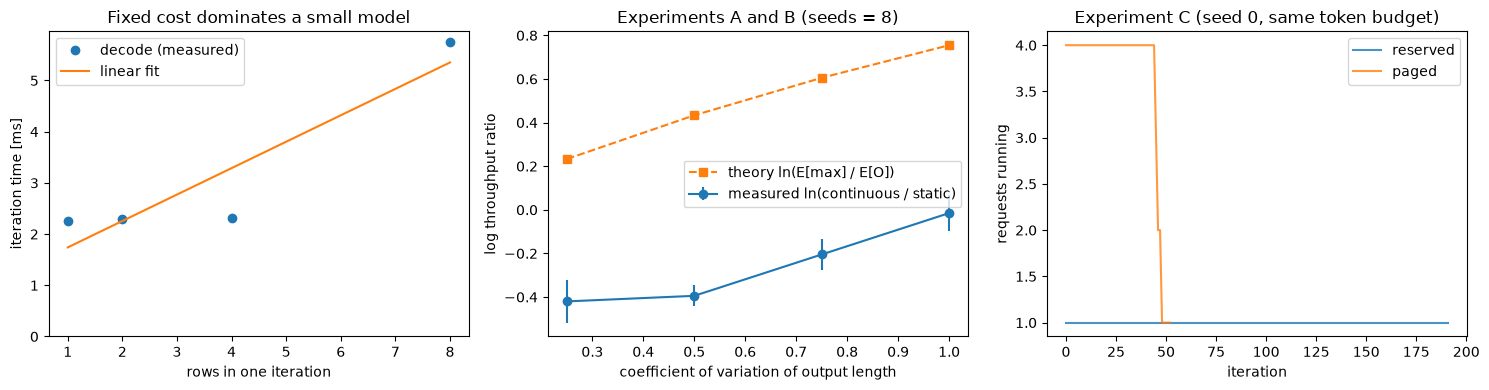

In [17]:
# --- 図: 1 反復の時間、スループットの比と変動係数、実験 C の実行中の要求数 ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
_rows = [r for r, _ in DECODE_SAMPLES]
axes[0].plot(_rows, [t * 1000 for _, t in DECODE_SAMPLES], "o", label="decode (measured)")
axes[0].plot(_rows, [COST_MODEL.decode_seconds(r) * 1000 for r in _rows], "-", label="linear fit")
axes[0].set_xlabel("rows in one iteration")
axes[0].set_ylabel("iteration time [ms]")
axes[0].set_ylim(bottom=0)
axes[0].set_title("Fixed cost dominates a small model")
axes[0].legend()
_x = np.array(VARIATION_LEVELS)
if AB_RUNS:
    axes[1].errorbar(_x, [LN_RATIO[variation].mean() for variation in VARIATION_LEVELS], yerr=[LN_RATIO[variation].std(ddof=1) / math.sqrt(N_SEEDS) for variation in VARIATION_LEVELS], fmt="o-", label="measured ln(continuous / static)")
axes[1].plot(_x, [math.log(THEORY_RATIO[variation]) for variation in VARIATION_LEVELS], "s--", label="theory ln(E[max] / E[O])")
axes[1].set_xlabel("coefficient of variation of output length")
axes[1].set_ylabel("log throughput ratio")
axes[1].set_title(f"Experiments A and B (seeds = {N_SEEDS})")
axes[1].legend()
for _kind in (("reserved", "paged") if C_RUNS else ()):
    axes[2].plot(C[(0, _kind)]["active_series"], label=_kind, alpha=0.8)
axes[2].set_xlabel("iteration")
axes[2].set_ylabel("requests running")
axes[2].set_title("Experiment C (seed 0, same token budget)")
axes[2].legend()
plt.tight_layout()
plt.show()

### 6.9 観察 D(最大バッチサイズ・到着の速さと、スループット・待ち時間)

In [18]:
# --- 6.9 節: 観察 D(最大バッチサイズ・到着の速さと、スループット・待ち時間。判定なし) ---
_d_stage = STAGES[STAGE]
print(f"到着率 = 比 × 基準の到着率 {LAMBDA_REFERENCE:.3f} 要求/秒(オフラインの処理能力)。要求 {NUM_REQUESTS_OBSERVATION} 件、出力長の変動係数 {VARIATION_C}、シード数 {_d_stage['observation_seeds']}(値はシードの平均)")
print(f"{'比':>5}{'最大バッチ':>9}{'スループット':>13}{'最初のトークン平均':>16}{'95 パーセンタイル':>9}{'出力あたり':>11}{'待ち行列':>9}{'反復あたり':>11}")
for _rho in _d_stage["rates"]:
    for _b in _d_stage["batch_sizes"]:
        _rows = [D[(_rho, _b, s)] for s in range(_d_stage["observation_seeds"])]
        print(f"{_rho:>5.1f}{_b:>9}{np.mean([r['throughput'] for r in _rows]):>13.1f}{np.mean([r['time_to_first_token_mean'] for r in _rows]) * 1000:>14.0f} ms"
              f"{np.mean([r['time_to_first_token_p95'] for r in _rows]) * 1000:>7.0f} ms{np.mean([r['time_per_output_token_mean'] for r in _rows]) * 1000:>9.1f} ms"
              f"{np.mean([r['queue_wait_mean'] for r in _rows]) * 1000:>7.0f} ms{np.mean([r['mean_iteration_seconds'] for r in _rows]) * 1000:>9.2f} ms")

到着率 = 比 × 基準の到着率 85.105 要求/秒(オフラインの処理能力)。要求 24 件、出力長の変動係数 0.5、シード数 2(値はシードの平均)
    比    最大バッチ       スループット       最初のトークン平均95 パーセンタイル      出力あたり     待ち行列      反復あたり
  0.4        1        187.5            17 ms     45 ms      2.8 ms     13 ms     3.04 ms
  0.4        2        187.4             8 ms     22 ms      3.8 ms      4 ms     3.45 ms
  0.4        4        187.9             6 ms     11 ms      4.7 ms      2 ms     4.09 ms
  0.4        8        187.1             9 ms     18 ms      6.0 ms      3 ms     5.28 ms
  0.8        1        298.3            66 ms    110 ms      3.0 ms     62 ms     3.22 ms
  0.8        2        340.7            20 ms     43 ms      4.3 ms     17 ms     3.93 ms
  0.8        4        354.9             9 ms     16 ms      6.0 ms      4 ms     4.61 ms
  0.8        8        345.5             8 ms     14 ms      7.3 ms      3 ms     5.20 ms
  1.2        1        327.0            92 ms    176 ms      2.8 ms     88 ms     2.92 ms
  1.2        2        386.0        

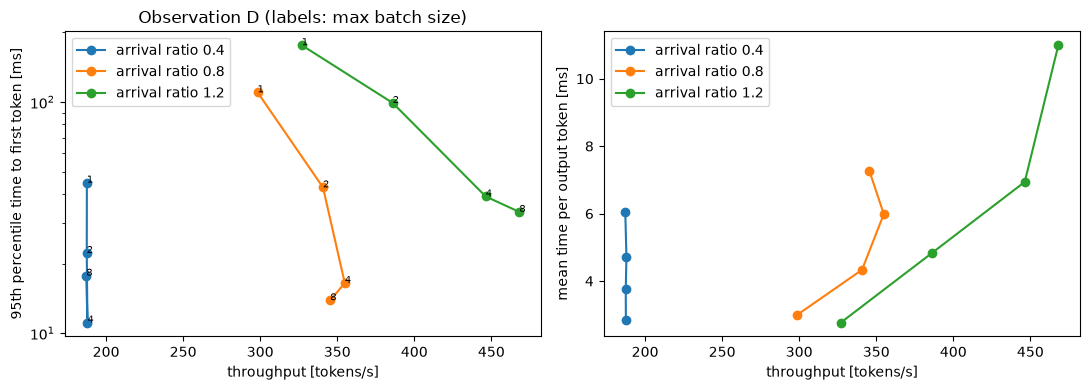

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for _rho in _d_stage["rates"]:
    _points = []
    for _b in _d_stage["batch_sizes"]:
        _rows = [D[(_rho, _b, s)] for s in range(_d_stage["observation_seeds"])]
        _points.append((np.mean([r["throughput"] for r in _rows]), np.mean([r["time_to_first_token_p95"] for r in _rows]) * 1000, np.mean([r["time_per_output_token_mean"] for r in _rows]) * 1000))
    axes[0].plot([p[0] for p in _points], [p[1] for p in _points], "o-", label=f"arrival ratio {_rho}")
    axes[1].plot([p[0] for p in _points], [p[2] for p in _points], "o-", label=f"arrival ratio {_rho}")
    for (_x_, _y_, _), _b in zip(_points, _d_stage["batch_sizes"], strict=True):
        axes[0].annotate(str(_b), (_x_, _y_), fontsize=7)
axes[0].set_yscale("log")
axes[0].set_xlabel("throughput [tokens/s]")
axes[0].set_ylabel("95th percentile time to first token [ms]")
axes[0].set_title("Observation D (labels: max batch size)")
axes[0].legend()
axes[1].set_xlabel("throughput [tokens/s]")
axes[1].set_ylabel("mean time per output token [ms]")
axes[1].legend()
plt.tight_layout()
plt.show()

### 6.10 観察 E(ブロックの大きさ・接頭辞の共有)

In [20]:
# --- 6.10 節: 観察 E(ブロックの大きさと内部の断片化・1 反復の時間 / 接頭辞の共有。判定なし) ---
_e_seeds = range(STAGES[STAGE]["observation_seeds"])
print(f"E1: 最大バッチサイズ {MAX_BATCH_SIZE}、要求 {NUM_REQUESTS_OBSERVATION} 件、出力長の変動係数 {VARIATION_C}(値はシードの平均)。無駄な枠 = 割り当てたが使っていない枠")
print(f"{'方式':<9}{'ブロック':>8}{'無駄な枠(平均)':>14}{'要求あたり':>10}{'理論 (b-1)/2':>13}{'使用率':>8}{'反復あたり':>11}{'スループット':>13}")
E1_ROWS = []
for _kind, _size in sorted({(k[0], k[1]) for k in E1}, key=lambda t: (t[0] != "paged", t[1])):
    _rows = [E1[(_kind, _size, s)] for s in _e_seeds]
    _wasted = np.mean([r["wasted_tokens_mean"] for r in _rows])
    _per_request = np.mean([r["wasted_tokens_mean"] / r["active_mean"] for r in _rows])
    E1_ROWS.append((_kind, _size, _wasted, _per_request))
    print(f"{_kind:<9}{_size:>8}{_wasted:>14.1f}{_per_request:>10.2f}{(_size - 1) / 2 if _kind == 'paged' else float('nan'):>13.2f}{np.mean([r['utilization'] for r in _rows]):>8.3f}"
          f"{np.mean([r['mean_iteration_seconds'] for r in _rows]) * 1000:>9.2f} ms{np.mean([r['throughput'] for r in _rows]):>13.1f}")
print(f"E2: system prompt {SYSTEM_PROMPT_LENGTH} トークン(ブロック {BLOCK_SIZE} の {SYSTEM_PROMPT_LENGTH // BLOCK_SIZE} つ分)を全要求が共有。到着率 {RHO_LEVELS[0]} × 基準(値はシードの平均)")
print(f"{'接頭辞の共有':<12}{'使用ブロック(平均)':>16}{'同(最大)':>10}{'共有で再利用したブロック':>20}{'最初のトークン平均':>16}{'95 パーセンタイル':>9}{'スループット':>13}")
for _flag in (False, True):
    _rows = [E2[(_flag, s)] for s in _e_seeds]
    print(f"{('あり' if _flag else 'なし'):<12}{np.mean([r['units_mean'] for r in _rows]):>16.1f}{np.mean([r['units_peak'] for r in _rows]):>10.1f}{np.mean([r['prefix_hit_blocks'] for r in _rows]):>20.1f}"
          f"{np.mean([r['time_to_first_token_mean'] for r in _rows]) * 1000:>14.0f} ms{np.mean([r['time_to_first_token_p95'] for r in _rows]) * 1000:>7.0f} ms{np.mean([r['throughput'] for r in _rows]):>13.1f}")

E1: 最大バッチサイズ 4、要求 24 件、出力長の変動係数 0.5(値はシードの平均)。無駄な枠 = 割り当てたが使っていない枠
方式           ブロック      無駄な枠(平均)     要求あたり   理論 (b-1)/2     使用率      反復あたり       スループット
paged           1           0.0      0.00         0.00   1.000     9.50 ms        397.6
paged           2           1.8      0.50         0.50   0.935     8.32 ms        453.9
paged           4           5.5      1.50         1.50   0.826     5.78 ms        631.9
paged           8          12.3      3.39         3.50   0.679     5.01 ms        727.8
paged          16          32.8      9.00         7.50   0.443     4.68 ms        778.8
reserved      256         907.1    248.84          nan   0.028     6.95 ms        525.1
E2: system prompt 8 トークン(ブロック 2 の 4 つ分)を全要求が共有。到着率 0.4 × 基準(値はシードの平均)
接頭辞の共有            使用ブロック(平均)     同(最大)        共有で再利用したブロック       最初のトークン平均95 パーセンタイル       スループット
なし                       7.9      18.0                 0.0             4 ms      9 ms        163.2
あり                       6.8      13.0             

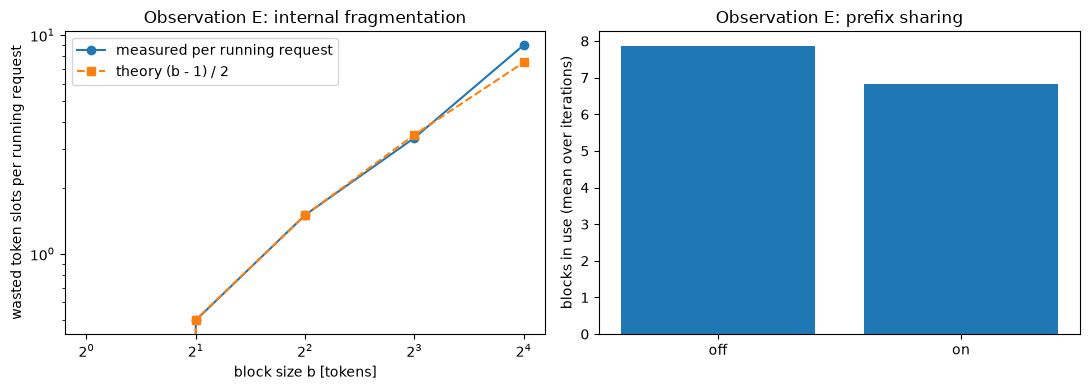

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
_paged = [(s, w, p) for k, s, w, p in E1_ROWS if k == "paged"]
axes[0].plot([s for s, _, _ in _paged], [p for _, _, p in _paged], "o-", label="measured per running request")
axes[0].plot([s for s, _, _ in _paged], [(s - 1) / 2 for s, _, _ in _paged], "s--", label="theory (b - 1) / 2")
axes[0].set_xscale("log", base=2)
axes[0].set_yscale("log")
axes[0].set_xlabel("block size b [tokens]")
axes[0].set_ylabel("wasted token slots per running request")
axes[0].set_title("Observation E: internal fragmentation")
axes[0].legend()
_flags = ("off", "on")
axes[1].bar(_flags, [np.mean([E2[(f, s)]["units_mean"] for s in _e_seeds]) for f in (False, True)])
axes[1].set_ylabel("blocks in use (mean over iterations)")
axes[1].set_title("Observation E: prefix sharing")
plt.tight_layout()
plt.show()

### 6.11 不変条件のアサーション

In [22]:
# --- 6.11 節: 不変条件のアサーション(揃っているはずの量を、実行時に確かめる) ---
assert len(RESULTS) == len(SPECS) == len(set(SPECS)), "条件が重複しているか、実行されていない条件がある"
assert len(SPECS) == len(planned_runs(STAGE)) - (0 if AB_RUNS else sum(s.experiment == "AB" for s in planned_runs(STAGE))) - (0 if C_RUNS else sum(s.experiment == "C" for s in planned_runs(STAGE)))
for _variation in (VARIATION_LEVELS if AB_RUNS else ()):
    for _s in SEEDS_ABC:  # 実験 A・B: 2 つの方式が、まったく同じ負荷・同じ KV キャッシュの設定で比べられている
        assert AB[(_variation, _s, "continuous")]["digest"] == AB[(_variation, _s, "static")]["digest"]
        assert AB[(_variation, _s, "continuous")]["output_mean"] == AB[(_variation, _s, "static")]["output_mean"]
        assert AB[(_variation, _s, "continuous")]["preemptions"] == AB[(_variation, _s, "static")]["preemptions"] == 0
assert PAGED_BLOCKS_C * BLOCK_SIZE == RESERVED_SLOTS_C * MODEL_MAX_LENGTH, "実験 C の 2 つの方式の予算(トークン枠の総数)が一致しない"
for _s in (SEEDS_ABC if C_RUNS else ()):
    assert C[(_s, "paged")]["digest"] == C[(_s, "reserved")]["digest"] == load_digest(make_requests(VARIATION_C, _s))
for _spec in SPECS[:: max(1, len(SPECS) // 20)]:  # 負荷の生成が決定的(同じシード・同じ条件から同じ負荷)
    assert load_digest(spec_requests(_spec)) == RESULTS[_spec]["digest"]
assert set(AB) == ({(variation, s, n) for variation in VARIATION_LEVELS for s in SEEDS_ABC for n in ("continuous", "static")} if AB_RUNS else set())
assert all(v["throughput"] > 0 for v in RESULTS.values())
assert TIMING_VARIATION >= 0 and DECODE_SAMPLES[0][0] == 1
print(f"不変条件を確認した(実行 {len(RESULTS)} 回。方式間で負荷が同一、実験 C の予算が一致、負荷の生成が決定的、全要求が出力長どおりに生成)")

不変条件を確認した(実行 120 回。方式間で負荷が同一、実験 C の予算が一致、負荷の生成が決定的、全要求が出力長どおりに生成)


### 6.12 判定結果の一覧

In [23]:
print(f"判定結果(計画 {STAGE}: {STAGES[STAGE]['change']}、実験 A・B・C のシード数 {N_SEEDS}、単体テスト {UNIT_TEST_COUNT} 件、前提条件 P0 {'成立' if P0 else '不成立'})")
for _name, _r in [("A", A_RESULT)] + list(B_RESULTS.items()) + [("C", C_RESULT)]:
    _pre = "・".join(f"{k} {'成立' if v else '不成立'}" for k, v in _r["preconditions"].items())
    if math.isnan(_r["delta"]):
        print(f"  実験 {_name}: 実行を省いた、前提条件 {_pre}、最終判定 {_r['verdict']}")
    else:
        print(f"  実験 {_name}: 対比量 {_r['delta']:+.4f}、標準偏差 {_r['sigma']:.4f}、閾値 {SIGMA_MULTIPLIER * _r['sigma']:.4f}、前提条件 {_pre}、"
              f"判定関数の結果 {_r['computed']}、最終判定 {_r['verdict']}")
_b_all = [r["verdict"] for r in B_RESULTS.values()]
print("  実験 B の読み方(宣言どおり): " + ("3 つの段がすべて支持 = 変動係数とともに比が単調に大きくなる" if all(v == "支持" for v in _b_all)
      else "いずれかの段が反証 = 単調ではない" if "反証" in _b_all else "支持以外の段がある(判定不能・前提不成立を含む)。単調増加は部分的にしか言えない"))
print(f"  全体の経過時間 {(time.time() - NOTEBOOK_START_TIME) / 60:.1f} 分(予算 {SESSION_BUDGET_SECONDS / 60:.0f} 分)")

判定結果(計画 0: (削らない)、実験 A・B・C のシード数 8、単体テスト 57 件、前提条件 P0 成立)
  実験 A: 対比量 -0.0150、標準偏差 0.0830、閾値 0.1660、前提条件 P0 成立・P1 成立・P2 成立・P3 成立、判定関数の結果 判定不能、最終判定 判定不能
  実験 B1: 対比量 +0.0256、標準偏差 0.1089、閾値 0.2179、前提条件 P0 成立・P1 成立・P2 成立、判定関数の結果 判定不能、最終判定 判定不能
  実験 B2: 対比量 +0.1897、標準偏差 0.0852、閾値 0.1704、前提条件 P0 成立・P1 成立・P2 成立、判定関数の結果 支持、最終判定 支持
  実験 B3: 対比量 +0.1898、標準偏差 0.1084、閾値 0.2169、前提条件 P0 成立・P1 成立・P2 成立、判定関数の結果 判定不能、最終判定 判定不能
  実験 C: 対比量 +2.7567、標準偏差 0.0330、閾値 0.0661、前提条件 P0 成立・P1 成立・P4 成立・P5 成立、判定関数の結果 支持、最終判定 支持
  実験 B の読み方(宣言どおり): 支持以外の段がある(判定不能・前提不成立を含む)。単調増加は部分的にしか言えない
  全体の経過時間 0.9 分(予算 120 分)


## 7. 結果・考察 / Results and Discussion

本番実行の後に、実際のセル出力の数値と突き合わせて書く。ここには、書く内容の一覧だけを置く。事前に宣言した判定基準による結論と、結果を見た後に立てた解釈は、節または段落を分けて書く。

### 本番実行の後に更新が必要な箇所

- 1.2 節の本番実行の結果の要約(判定の表)。
- 7 章の各節の本文(下の一覧に沿って、本番のセル出力と突き合わせて書く。縮小スケールの数値は使わない)。
- セットアップセルの`SMOKE_TEST`(本番の出力を持つノートブックでは`False`)と、全セルの出力(本番の実行で置き換わる)。
- 付録 A の実行の記録(実行したコミット・選ばれた計画・実行時間)。
- リポジトリの`theories/README.md`の学習順序表の「判定」の列と、「各トピックの詳細」の本番の結果。

### 7.1 実行環境と実行時間

- セットアップセルの印字を出典に、GPU の種類・ライブラリの版・コミット・実行日時を書く。
- 選ばれた計画(削る段階)と、見積もりに対する実測の比、全体の経過時間(コーパスの取得・単体テスト・パイロットを含む)。

### 7.2 正しさ(前提条件 P0)

- 6 つの場合(連続・paged、連続・予約方式、static、接頭辞の共有、退避と再計算、到着の間の待ち)それぞれの、トークン列の一致、logits の差と許容誤差の比、僅差の手の数。
- 接頭辞の共有と退避の経路が実際に通ったこと。P0 の成否。

### 7.3 1 反復の時間と固定費

- decode と prefill の一次式の係数、行数 1 に対する最大の行数の時間の倍率。固定費が支配的か。
- 見積もりの検証(モデルなしの反復の列と費用モデルによる見積もりと、実測の比)。

### 7.4 実験 A

- 判定(対比量・標準偏差・閾値・前提条件の成否・最終判定)。
- 考察に使う主な数値: 連続と static のスループット、理論の比と実測の比の差、反復の回数の比、forward の回数の比、static の無駄な行の割合。
- 結論の範囲: 小型モデルの固定費が支配的な条件での結論であること。

### 7.5 実験 B(B1・B2・B3)

- 段ごとの判定と、宣言した組み合わせの読み方による結論。
- 理論の比と実測の比の関係(水準ごと)。理論からのずれの向きと大きさ。

### 7.6 実験 C

- 判定。実行中の要求数、スループット、使用中の枠の割合、退避の回数。
- 予約方式の同時に処理できる数と、PagedAttention の実行中の要求数の関係。

### 7.7 観察 D(判定なし)

- 最大バッチサイズと到着の速さごとの、スループット・最初のトークンまでの時間・出力トークンあたりの時間・待ち行列の待ち時間の表と図。
- **アプリの段階 2 で最大バッチサイズを決める材料としての、結果の読み方**: スループットが飽和し始める最大バッチサイズ、出力トークンあたりの時間が伸び始める最大バッチサイズ、到着の速さ(混み具合)によって最初のトークンまでの時間がどう変わるか。どの指標を優先するかで、選ぶ値がどう変わるか。
- 結果から言えないこと(1 つのモデル・1 つのデバイス・合成の負荷)。

### 7.8 観察 E(判定なし)

- ブロックの大きさごとの、内部の断片化と理論 $(b - 1)/2$ との比較、1 反復の時間。最大長の分を確保する方式(ブロックの大きさ 256 にあたる)との関係。
- 接頭辞の共有の有無による、使用中のブロック数と最初のトークンまでの時間の変化。

### 7.9 支持以外の実験の「なぜそうなったか」(事後的な解釈。検証済みの結論ではない)

支持以外(反証・判定不能・前提不成立)になった実験ごとに、次の 4 つを書く。前提不成立の実験では、「なぜ前提が崩れたか」と「判定関数の参考値がなぜその向きになったか」を別々に扱う。

- 原因の候補(設計と、実際に起きた現象の両面から)。
- 根拠(セル出力の診断量のうち、その候補を支持または否定するもの。数値がない候補はその旨)。
- 確かめる方法(追加の実験。実行はしない)。
- 教訓(次のトピックの設計に持ち越せる一般的な事項)。

### 7.10 アプリ(段階 2)への示唆

- スケジューラ・メモリ管理・最大バッチサイズ・ブロックの大きさを、アプリの設計にどう持ち込むか。本トピックで実装した`src/serving/`のうち、アプリから再利用する部分。

### 7.11 制約と一般化の範囲

- 小型 GPT では KV キャッシュが T4 のメモリに比べて小さく、メモリの制約は実際にはかからない。実験 C の予算は人工的に決めた。
- 小型モデルの 1 反復の時間は固定費が支配的になりうる。スループットの差には forward の回数の差が強く効く。大きなモデルや長い文脈では、計算量が効いて結論が変わりうる。
- 結論が成り立つ範囲: 1 つのモデル・1 つのデバイス・合成の負荷・貪欲法・FP32・出力長を割り当てた長さで止める評価・prefill と decode を別々に forward する実装。

### 7.12 次のトピックへの教訓

- 設計に持ち越せる一般的な事項(検出力の事前確認、固定費の見積もり、前提条件の設計など)。

## 付録 / Appendix

付録は、実験の運用の記録(手順、宣言の補足、実行計画、縮小規則、実装の詳細)である。本文の理解には必要ない。

### 付録 A. 実行の手順

1. 実行するコミットが GitHub に push 済みであることを確かめる(Colab はリポジトリの既定のブランチを clone する)。Google Colab で GPU(T4)のランタイムを選び、ノートブックを開く。
2. セットアップセルの`SMOKE_TEST`を`False`にする(`True`は縮小スケールの動作確認)。
3. 「ランタイム」→「すべてのセルを実行」を選ぶ。**本番は 1 回で完結させる。** 本番(`SMOKE_TEST = False`)は、追跡しているファイルに未コミットの変更がない状態でないと、実験の前に停止する。
4. セットアップセルで、インストールにより版が入れ替わったパッケージの食い違いが検出されたときは、カーネルが自動で終了する。再接続後、もう一度「すべてのセルを実行」を選ぶ。
5. 6.5 節の見積もりが予算(120 分)を超えるときは、最も下位の計画でも収まらない場合に限り、実験の前に停止する。この場合は実験の結果の情報を何も得ていない。

Hugging Face Hub へのアップロードはない(学習を行わず、生成物はセルの出力だけである)。

### 付録 B. 実験の宣言の補足

#### B.1 対比量と標準偏差の導出

- **実験 A**: シード $s$ ごとの差 $d_s = \ln \Theta_{\mathrm{K},s} - \ln \Theta_{\mathrm{S},s}$ は、同じ負荷での対応付きの差である。$\Delta_A$ はその平均で、標準偏差は $\mathrm{sd}_s(d_s) / \sqrt{n}$ を基本とする。シード数が少ないと標本標準偏差が小さく出ることがあるので、**下限** として、パイロットで測った同じ条件の反復の対数スループットの標準偏差 $\sigma_{\mathrm{rep}}$ から、2 つの条件(K、S)が独立に揺らぐとした値 $\sqrt{2}\,\sigma_{\mathrm{rep}} / \sqrt{n}$ を置く。標準偏差は 2 つの大きい方。
- **実験 B**: 水準が違えば負荷の分布が違うので、水準 $c_k$ と $c_{k+1}$ の $r_s$ は独立とみなす。$\mathrm{var}(\bar{r}(c_{k+1}) - \bar{r}(c_k)) = (\mathrm{var}_s(r(c_{k+1})) + \mathrm{var}_s(r(c_k))) / n$。下限は、4 つの条件(2 水準 × K、S)が独立に揺らぐとした $2\sigma_{\mathrm{rep}} / \sqrt{n}$。
- **実験 C**: $d_s = \bar{N}_{\mathrm{P},s} - \bar{N}_{\mathrm{R},s}$ の標準偏差 $\mathrm{sd}_s(d_s) / \sqrt{n}$。実行中の要求数はスケジュール(要求の列とメモリの条件)だけで決まり、実時間に依存しないので、反復のばらつきの下限は置かない。

#### B.2 検出力の事前確認

判定の閾値は対比量の標準偏差の 2 倍なので、シード間のばらつきが大きいと、仮説が正しくても判定不能になる。そこで、本番の前のパイロットで、**単一の条件の値のシード間の標準偏差** を測り、本番のシード数で検出できる最小の効果量(閾値の見込み $= 2\sigma$)を、誤差伝播で見積もる。測るのは対比量の向きの情報を含まない量だけである。

- 測る量: 同じ条件の反復の対数スループットの標準偏差 $\sigma_{\mathrm{rep}}$。単一の条件(連続、static)のスループットの対数の、シード間の標準偏差 $\sigma_{\mathrm{K}}$、$\sigma_{\mathrm{S}}$(負荷が違うシード 3 つ、変動係数 1.0)。実験 C は、P と R それぞれの実行中の要求数の、シード間の標準偏差(モデルを実行せずスケジューラだけで計算できる)。
- 見積もり: 条件間の相関は未知なので、**独立を仮定した見積もり** である(対応付きで相関が正なら、実際の標準偏差はこれ以下になりうる)。比の標準偏差は $\sigma_{\mathrm{ratio}} = \sqrt{\sigma_{\mathrm{K}}^2 + \sigma_{\mathrm{S}}^2}$。実験 A の検出できる最小の効果は $2 \max(\sigma_{\mathrm{ratio}} / \sqrt{n},\ \sqrt{2}\,\sigma_{\mathrm{rep}} / \sqrt{n})$、実験 B の各段は $2 \max(\sqrt{2}\,\sigma_{\mathrm{ratio}} / \sqrt{n},\ 2\sigma_{\mathrm{rep}} / \sqrt{n})$、実験 C は $2\sqrt{\sigma_{\mathrm{P}}^2 + \sigma_{\mathrm{R}}^2} / \sqrt{n}$。
- 想定される効果の大きさ: 理論の予測の **0.5 倍**(保守側)。実験 A は $\ln \rho_B$($c_v = 1.0$)の 0.5 倍、実験 B の各段は隣り合う水準の $\ln \rho_B$ の差の 0.5 倍、実験 C は「予算 / (書き出しの平均 + 出力長の平均の半分 + ブロックの空きの平均 + 余白のブロック) と最大バッチサイズの小さい方」から予約方式の同時に処理できる数を引いた値の 0.5 倍。0.5 倍とするのは、スループットの比は、固定費と入れ替えの forward の分だけ、反復の回数の比(理論)より小さくなる見込みだからである。
- 規則: 検出できる最小の効果が、保守側の予測以下になるシード数だけを、実行計画の候補に残す。最上位のシード数でも満たさない場合は、設計を見直さずに本番に進む(本番は 1 回で完結させる)。その場合の判定不能は、効果がないことではなく、検出力の不足として読む。

#### B.3 前提条件の閾値の根拠

- **P1**: 4 倍は、標本抽出のばらつきに対する十分な余裕(正規近似で、片側が外れる確率の両側の合計が約 $10^{-4}$)。標準偏差は、分布から $4000$ 回の乱数で見積もる(標本の個数は全シードの要求数の合計)。
- **P2**: 変動係数の閾値 0.05 は、同じ条件の反復の対数スループットの標準偏差 $\sigma_{\mathrm{rep}}$ がこの値のとき、実験 B の標準偏差の下限 $2\sigma_{\mathrm{rep}} / \sqrt{n}$ の 2 倍(閾値の下限)が、8 シードで、実験 B の最小の段の保守側の予測(6.5 節の出力)を下回るように選んだ値である。反復のばらつきがこれを超えると、実験 B の段を検出できなくなる。
- **P3**: 理論の比 1.5 は、改善の余地(static batching の無駄な行の割合 $1 - 1/\rho_B$ が約 1/3 以上)がある水準を選ぶ値。比がこれ未満のときは、無駄が小さく、差が出ない。
- **P4・P5**: P4 は実験 C の設計の制約(予約方式が制約を受けること)、P5 は確保した枠の無駄が大きいこと(使う長さの平均が確保する長さの半分以下)。いずれも、方式の結果ではなく、予算と負荷の設計だけで決まる。

#### B.4 揃えた量と揃えなかった量

| 実験 | 揃えた量 | 揃えなかった量(介入) |
|---|---|---|
| A、B | モデルの重み、要求の列(書き出し・出力長・到着)、最大バッチサイズ、KV キャッシュの方式(PagedAttention、予算に制約なし)、ブロックの大きさ、実行ループ、時計 | スケジューラ(static / continuous) |
| C | モデルの重み、要求の列、最大バッチサイズ、スケジューラ(continuous)、予算(トークン枠の総数)、実行ループ、時計 | KV キャッシュの方式(最大長の分を確保 / PagedAttention) |

**揃えられない点**: 実験 A・B の static batching は終わった行を計算に残すので、forward に入る行数が違う。これは介入そのもの(スケジューラの違い)に含まれる。実験 C の PagedAttention は実行中の要求 1 つあたり 1 ブロックの余白を残して受け入れる(退避の頻度を抑えるための方式の一部)。

#### B.5 水準の刻み

- 変動係数は **等間隔**(0.25 刻み)にする。理論の比は、正規近似で変動係数にほぼ線形に増える(3.2 節)ので、水準の刻みを効果の尺度(線形)に揃える。
- 最大バッチサイズとブロックの大きさは **等比**(2 倍刻み)にする。固定費の分担も断片化の大きさも、2 倍ごとに一定の割合で変わると想定されるため。
- 到着の速さの比 $\{0.4, 0.8, 1.2\}$ は、処理能力(比 1)をまたぐ等間隔の 3 水準である。

#### B.6 閾値を超えうる状態の列挙

- **実験 A**: $\Delta_A$ が閾値を超えるのに仮説と矛盾する状態は、スケジューラ以外の違いで差が出る場合である。(i)実行の順番による時間の偏り(同じシードの 2 つの方式は、実行順を交互に入れ替える)、(ii)負荷の違い(同じ要求の列であることを、負荷のダイジェストの一致で確かめる)、(iii)実行ごとの準備の時間(計算の時間に含めない)。いずれも設計で排除した。
- **実験 B**: 各段は 1 つの比較で、部分の取り違えは起きない。3 段を合わせた読み方は事前に宣言した。
- **実験 C**: 対比量(実行中の要求数)は仮説の主張そのものである。PagedAttention が退避を繰り返すと、実行中の要求数が増えてもスループットは下がりうるが、それは仮説(実行中の数が多い)とは矛盾しない。退避の回数とスループットを診断量にする。

#### B.7 実験 A と B の関係

実験 A の実行は、実験 B の最上位の水準(変動係数 1.0)の実行と同じである。実行を共有するが、検証事項は別である(A は水準 1.0 での条件 K と S の比較、B は水準間の比の変化)。

### 付録 C. 実行計画・スケーリングの計測・パイロット

#### C.1 削る段階と自動選択

本番は Colab の 1 セッション(T4 で 120 分)で完結させる。本番の冒頭で測った時間(6.3 節)とパイロット(6.4 節。その時間も予算に含める)の後の経過時間から、各段階の残りの実行時間を見積もり、**検出力の確認(6.5 節)を通った段階のうち、予算に収まる最小の番号** を選ぶ。選択は見積もりと経過時間のみに基づき、どの実験の結果も参照しない。最も下位の段階でも収まらなければ、実験の前に停止する。

| 段階 | 変更 | 実験 A・B・C のシード数 | 観察 D・E のシード数 | 観察 D の到着の速さ | 観察 D の最大バッチサイズ | 観察 E のブロックの大きさ |
|---|---|---|---|---|---|---|
| 0 | (削らない) | 8 | 2 | 0.4・0.8・1.2 | 1・2・4・8・16・32 | 4・8・16・32・64 |
| 1 | 観察のシード数を 1 にする | 8 | 1 | 同上 | 同上 | 同上 |
| 2 | 観察の水準を 1 つおきにする | 8 | 1 | 0.4・1.2 | 1・4・16 | 4・16・64 |
| 3 | 実験 A・B・C のシード数を 5 にする | 5 | 1 | 0.4・1.2 | 1・4・16 | 4・16・64 |
| 4 | 実験 A・B・C のシード数を 3 にする | 3 | 1 | 0.4・1.2 | 1・4・16 | 4・16・64 |
| 5 | 実験 A・B・C のシード数を 2 にする | 2 | 1 | 0.4・1.2 | 1・4・16 | 4・16・64 |

**この順にした理由**: (1)判定を設けない観察を最初に削る。削っても判定に影響しない。(2)観察の中では、シード数を先に下げ、その次に水準を下げる(水準は表の見出しの比較に使うため、残すものの両端を保つ)。(3)実験 A・B・C のシード数を最後に削る。シード数が減ると閾値が大きくなり、判定不能になりやすいので、検出力の確認(B.2)を通らない段階は外す。実験の水準(変動係数の 4 水準、負荷の要求数 $N$、最大バッチサイズ)は削らない。

**削る段階での前提条件**: P1 の許容幅は、段階のシード数で決まる標本の個数から自動で計算される。P2・P3・P4・P5 は段階によらない。

#### C.2 見積もりの方法

スケジューラとメモリ管理は、トークンの値に依存せず、出力長と到着時刻と予算だけで決まる。そこで、モデルを実行しない実行器(`DryRunner`)と、1 反復の時間の一次式による時計(`ModelClock`)で、実行と同じ反復の列を再現し、計算の時間を見積もる。見積もりは、定常状態の 1 反復の時間を反復数に比例させる(反復のウォームアップの後の中央値による一次式)。一次式の係数は、行数ごと・問い合わせのトークン数ごとに、ウォームアップの後に測った時間の中央値から最小二乗法で求める。

**見積もりの安全係数**: パイロットの実行(8 回)について、実測の計算時間を同じ条件の見積もりで割った比を求め、その最大値と 1.1 の大きい方を、学習以外の処理を含む全実行の見積もりに掛ける。実行ごとの準備の時間(ストアの確保、負荷の生成)は、パイロットで測った平均を加える。

#### C.3 スケーリングの計測

- **1 反復の時間**: decode は行数(1・2・4・8・16・32)、prefill は問い合わせのトークン数(行数 × 長さの 6 通り)について、ウォームアップ 5 回の後、30 回の中央値を測る。
- **要求数への依存**: 最も重い条件(最大バッチサイズ 1、要求 96 件)で、要求数 24・48・96 の 3 点の計算時間を測り、べき指数 $b$ を推定する。最大の点が本番の量そのものなので、外挿は要らない。
- **コーパスの取得**: 単発の取得(約 545 MB)で、外挿の対象にしない。経過時間に含める。

#### C.4 パイロットの内容

- 連続方式と static batching を、変動係数 1.0・最大バッチサイズ 16 の負荷で、パイロット専用のシード 90・91・92 に対して 1 回ずつ実行する(条件間の比較や対比量の計算はしない)。
- 連続方式を、シード 90 で 3 回(うち 1 回は上の実行)繰り返し、同じ条件の反復のスループットのばらつき(P2 と $\sigma_{\mathrm{rep}}$)を測る。
- 連続方式のスループットの中央値(トークン / 秒)を出力長の平均で割った値を、基準の到着率(要求 / 秒)とする。
- 実験 C の検出力の確認に使う、P と R の実行中の要求数を、モデルを実行せずに計算する。

### 付録 D. スモークテストの縮小規則

`SMOKE_TEST = True`は、コードの経路が最後まで通る動作確認だけが目的で、数値に意味はない(前提条件が成立しなくてよい)。縮小は、本番設定との構造(比率・順序関係・一致関係)を保つ。

| 項目 | 本番 | 縮小 | 保つ構造 |
|---|---|---|---|
| 要求数 $N$ | 128 | 32 | 最大バッチサイズの 8 倍 |
| 最大バッチサイズ $B$ | 16 | 4 | |
| 書き出しの長さ | 16〜48 | 2〜6 | 出力長の平均との比 2/3 |
| 出力長の平均 / 上限 | 48 / 192 | 6 / 24 | 上限は平均の 4 倍 |
| 実験 C のスロット数 | 4 | 1 | 最大バッチサイズの 1/4 |
| 既定のブロックの大きさ | 16 | 2 | 書き出しの平均の長さの 1/2 |
| 観察 E のブロックの大きさ | 4・8・16・32・64 | 1・2・4・8・16 | 2 倍刻みの等比、既定が中央 |
| 観察 D の最大バッチサイズ | 1・2・4・8・16・32 | 1・2・4・8 | 2 倍刻みの等比 |
| 観察の要求数 | 96 | 24 | 最大バッチサイズの 6 倍 |
| system prompt の長さ | 64 | 8 | 既定のブロックの 4 つ分 |

**本番と縮小で同じにする量**: 変動係数の水準、シード数の段階、判定の閾値(標準偏差の 2 倍)、前提条件の定義と閾値、到着の速さの比、モデルとその最大の文脈長(256)。**構造を保てない点**: モデルは同じなので、最大長の分を確保する方式の確保長(256)に対する、要求が実際に使う長さの割合(P5)は、縮小では本番より小さい。

### 付録 E. 生成物の置き場所・外部から取得するもの

- この実験が生成するものは、**セルの出力だけ**(判定、図、表)である。Hugging Face Hub へのアップロードはなく、`.cache/`にも何も置かない。
- 外部から取得するもの: トークナイザ(`kojikojiprg/ai-theories-tokenizer-en`)、008 のモデル(`kojikojiprg/ai-theories-small-gpt-en`の`main`)、コーパス(`kojikojiprg/ai-theories-corpus-en`の`corpus.txt`と`metadata.json`)、008 の事前学習に使ったコーパス(`kojikojiprg/ai-theories-corpus-en-pretraining`。検証用の範囲が事前学習の範囲の外にあることの確認に使う)。

### 付録 F. 実装の詳細

- **既存のコードを変えなかった理由**: `GPTLanguageModel.forward`の`positions`は全行共通の`(S,)`で、`KeyValueCache`は全行が同じ長さであることを前提にする。バッチの中の要求が別々の位置にいて、KV キャッシュの長さも違う推論サーバの用途には使えないので、`src/serving/runner.py`に、既存の層(正規化・順伝播ネットワーク・射影)の重みをそのまま使う forward を書いた。
- **添字による読み書き**: 新しい Key / Value は`keys[layer][first, second]`に書き込み、過去の Key / Value は`keys[layer][first, second]`を`(R, Lkv)`の添字で集める。最大長の分を確保する方式は`(スロット, 位置)`、PagedAttention は`(物理ブロック, ブロック内の位置)`を添字にする。添字の組み立て(ブロック表の参照)は 1 回の forward につき 1 回で、全層で共有する。
- **マスク**: 集めた位置 $j$ が Query の絶対位置以下のときだけ参加させる。短い行の埋めた部分は位置より後ろなので、同じ規則で除かれる。
- **時刻**: 各反復の開始と、prefill・decode の終了ごとに、デバイスの同期を取ってから読む。要求の最初のトークンの時刻は prefill の終了、最後のトークンの時刻は、そのトークンを生成した forward の終了である。
- **退避**: decode の前に、各要求の次のトークンの置き場所を用意し、足りなければ最後に実行に入れた要求を取り下げる(Key / Value を捨て、待ち行列の先頭に戻す)。再開のときは、書き出しとそれまでの生成を prefill し直す。取り下げた要求の最初のトークンの時刻は、最初の生成のときのものを保つ。実行中の要求を取り下げられない(予算が 1 要求の最大の長さより小さい)ときは、停止する。
- **許容誤差**: $\mathrm{tol} = D \sqrt{K_{\max}}\, \varepsilon \max(1, \max_v \lvert z_v \rvert)$。$D$ は直列に並ぶ行列積の段数(層ごとに 12 段 × 層数)、$K_{\max}$ は内積の長さの最大($d_{\mathrm{model}}$、順伝播ネットワークの中間次元、最大の文脈長の最大)、$\varepsilon$ は計算する型の機械イプシロン、$z_v$ は基準の logits の成分。
- **単体テスト**: `scripts/test_serving.py`。負荷の生成、ブロックの確保と解放の整合、書き込み時の複製、接頭辞の共有と捨て方、スケジューラの反復数、1 要求ずつの生成との一致(退避・接頭辞の共有・Grouped-Query Attention を含む)を確かめる。件数は 5.4 節の出力。